<a href="https://colab.research.google.com/github/rhemamfrancis/ML-Guided-CDK2-Drug-Repositioning/blob/main/CDK2_Drug_Repurposing_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Repositioning Approved Drugs to Target CDK2 in CDK4/6-Inhibitor-Resistant Breast Cancer
## Rhema Francis
###October 2026



In [ ]:
import requests
pid = "1H01"
r = requests.get(f"https://files.rcsb.org/download/{pid}.pdb")
print(f"{pid}: HTTP {r.status_code}; downloaded {len(r.content)} bytes")


1H01 HTTP 200
TITLE     CDK2 IN COMPLEX WITH A DISUBSTITUTED 2, 4-BIS ANILINO PYRIMIDINE CDK4 
TITLE    2 INHIBITOR                                                            
HETNAM     KCX LYSINE NZ-CARBOXYLIC ACID                                        
HETNAM     GOL GLYCEROL                                                         
HETNAM     FAL (2R)-1-[4-({4-[(2,5-DICHLOROPHENYL)AMINO]PYRIMIDIN-2-            
HETNAM   2 FAL  YL}AMINO)PHENOXY]-3-(DIMETHYLAMINO)PROPAN-2-OL                  
HETNAM     FBL (2S)-1-[4-({4-[(2,5-DICHLOROPHENYL)AMINO]PYRIMIDIN-2-            
HETNAM   2 FBL  YL}AMINO)PHENOXY]-3-(DIMETHYLAMINO)PROPAN-2-OL                  
1E1X HTTP 200
TITLE     HUMAN CYCLIN DEPENDENT KINASE 2 COMPLEXED WITH THE INHIBITOR NU6027   
HETNAM     ACE ACETYL GROUP                                                     
HETNAM     NW1 6-CYCLOHEXYLMETHYLOXY-5-NITROSO-PYRIMIDINE-2,4-DIAMINE           


# 1. Environment Setup
Mount Google Drive, install dependencies, and initialize molecular visualization tools.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip install pymol-open-source
!pip install mols2grid
!pip install rdkit
!pip install py3Dmol

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 18.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 79.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 71.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mols2grid]


In [ ]:
import rdkit
from rdkit import Chem

import py3Dmol
import mols2grid

import numpy as np
import pandas as pda
print(f'RDKit version used: {rdkit.__version__}')

RDKit version used: 2026.09.1


# 2. CDK2 Data Collection
Retrieve CDK2 activity measurements and the approved-drug library from ChEMBL.


In [ ]:
import requests, time, pandas as pd

# Sanity check: is CHEMBL301 human CDK2?
t = requests.get("https://www.ebi.ac.uk/chembl/api/data/target/CHEMBL301.json").json()
print(t["pref_name"], "|", t["organism"])

# Activities (same loop as your ALK notebook, new target)
acts, url = [], "https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL301&limit=1000&offset=0"
while url:
    d = requests.get(url, timeout=30).json()
    acts.extend(d["activities"]); print(len(acts), end=" ")
    nxt = d["page_meta"].get("next")
    url = f"https://www.ebi.ac.uk/{nxt.lstrip('/')}" if nxt else None
    time.sleep(0.5)
cdk2 = pd.DataFrame(acts).dropna(subset=["canonical_smiles"])
cdk2["pchembl_value"] = pd.to_numeric(cdk2["pchembl_value"], errors="coerce")
print("\nrecords:", len(cdk2), "| pChEMBL > 8:", (cdk2.pchembl_value > 8).sum())

Cyclin-dependent kinase 2 | Homo sapiens
1000 2000 3000 4000 5000 6000 7000 8000 9000 10000 10355 
records: 10344 | pChEMBL > 8: 412


In [ ]:
# Approved drugs (max_phase = 4)
drugs, url = [], "https://www.ebi.ac.uk/chembl/api/data/molecule.json?max_phase=4&limit=1000"
while url:
    d = requests.get(url, timeout=30).json()
    for m in d["molecules"]:
        s = (m.get("molecule_structures") or {}).get("canonical_smiles")
        if s: drugs.append({"ID": m["molecule_chembl_id"], "name": m.get("pref_name"), "smiles": s})
    nxt = d["page_meta"].get("next")
    url = f"https://www.ebi.ac.uk/{nxt.lstrip('/')}" if nxt else None
    time.sleep(0.5)
approved = pd.DataFrame(drugs)
print("approved drugs with structures:", len(approved))
approved.to_csv("approved_drugs.csv", index=False); cdk2.to_csv("cdk2_activities.csv", index=False)

approved drugs with structures: 3417


In [ ]:
!cp approved_drugs.csv cdk2_activities.csv /content/drive/MyDrive/

In [ ]:
print(approved.head(10))
print(approved.name.isna().sum(), "entries without a name")
print(approved.smiles.str.contains(r"\.").sum(), "with multiple fragments (salts)")

          ID            name  \
0    CHEMBL2        PRAZOSIN   
1    CHEMBL3        NICOTINE   
2    CHEMBL4       OFLOXACIN   
3    CHEMBL5  NALIDIXIC ACID   
4    CHEMBL6    INDOMETHACIN   
5  CHEMBL403       SULBACTAM   
6  CHEMBL404      TAZOBACTAM   
7    CHEMBL8   CIPROFLOXACIN   
8    CHEMBL9     NORFLOXACIN   
9  CHEMBL405     AMPHETAMINE   

                                              smiles  
0      COc1cc2nc(N3CCN(C(=O)c4ccco4)CC3)nc(N)c2cc1OC  
1                               CN1CCC[C@H]1c1cccnc1  
2   CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23  
3                    CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21  
4     COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1  
5          CC1(C)[C@H](C(=O)O)N2C(=O)C[C@H]2S1(=O)=O  
6  C[C@]1(Cn2ccnn2)[C@H](C(=O)O)N2C(=O)C[C@H]2S1(...  
7         O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O  
8          CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21  
9                                     CC(N)Cc1ccccc1  
0 entries without a name
1205 with multipl

# 3. Approved-Drug Library Preparation
Standardize structures, remove duplicates, apply PAINS and physicochemical filters.


In [ ]:
import pandas as pd
from rdkit import Chem, RDLogger
RDLogger.DisableLog('rdApp.*')   # silence RDKit warnings

approved = pd.read_csv("approved_drugs.csv")   # skip this line if `approved` is still in memory

library = approved.copy()
library["ROMol"] = library["smiles"].apply(Chem.MolFromSmiles)

print(f"Total number of molecules in library: {len(library)}")
print("Failed to parse:", library["ROMol"].isna().sum())
library = library.dropna(subset=["ROMol"]).reset_index(drop=True)
library.head()

Total number of molecules in library: 3417
Failed to parse: 0


,ID,name,smiles,ROMol
0,CHEMBL2,PRAZOSIN,COc1cc2nc(N3CCN(C(=O)c4ccco4)CC3)nc(N)c2cc1OC,<rdkit.Chem.rdchem.Mol object at 0x798f1766b300>
1,CHEMBL3,NICOTINE,CN1CCC[C@H]1c1cccnc1,<rdkit.Chem.rdchem.Mol object at 0x798f1766b370>
2,CHEMBL4,OFLOXACIN,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,<rdkit.Chem.rdchem.Mol object at 0x798f1766b3e0>
3,CHEMBL5,NALIDIXIC ACID,CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21,<rdkit.Chem.rdchem.Mol object at 0x798f1766b450>
4,CHEMBL6,INDOMETHACIN,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,<rdkit.Chem.rdchem.Mol object at 0x798f1766b4c0>


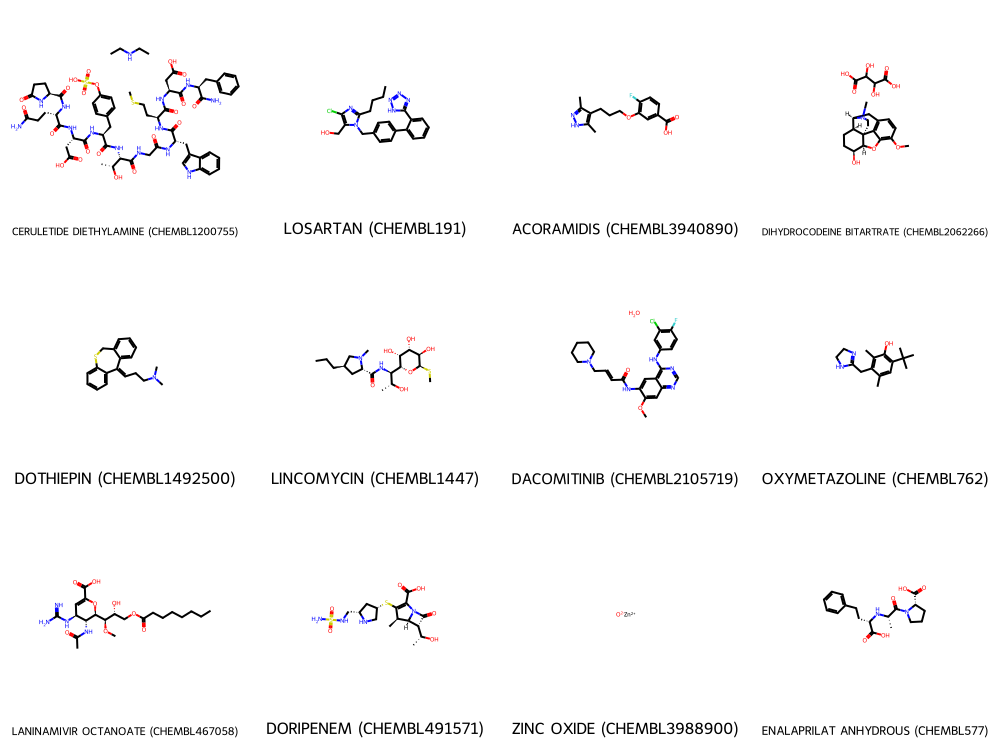

In [ ]:
from rdkit.Chem import Draw
sample = library.sample(12, random_state=1)
legends = [f"{row['name']} ({row['ID']})" for _, row in sample.iterrows()]
Draw.MolsToGridImage(list(sample["ROMol"]), molsPerRow=4, legends=legends, subImgSize=(250, 250))

In [ ]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

# Count molecules with more than one fragment (salts / counterions) before desalting
n_multi = sum(len(Chem.GetMolFrags(m)) > 1 for m in library["ROMol"])

# Keep only the largest fragment of each molecule
library["ROMol"] = library["ROMol"].apply(chooser.choose)

print(f"Molecules in library:                    {len(library)}")
print(f"Molecules with >1 fragment (desalted):   {n_multi}")

Molecules in library:                    3417
Molecules with >1 fragment (desalted):   1205


In [ ]:
from rdkit import Chem

# Canonicalize SMILES (his function), then drop failures and duplicates
def canonicalize(mol):
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

n0 = len(library)
library["canonical_smiles"] = library["ROMol"].apply(canonicalize)
library = library.dropna(subset=["canonical_smiles"])
n1 = len(library)
library = library.drop_duplicates(subset="canonical_smiles", keep="first").reset_index(drop=True)
n2 = len(library)

print(f"Loaded:                   {n0}")
print(f"After dropping failures:  {n1}")
print(f"After removing duplicates:{n2}  ({n1 - n2} duplicates removed)")

Loaded:                   3417
After dropping failures:  3417
After removing duplicates:2484  (933 duplicates removed)


In [ ]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
pains = FilterCatalog(params)

library["PAINS"] = library["ROMol"].apply(pains.HasMatch)

print(f"PAINS-flagged: {library['PAINS'].sum()} of {len(library)}")
library_clean = library[~library["PAINS"]].reset_index(drop=True)
print(f"After removing PAINS: {len(library_clean)}")
print(library.loc[library["PAINS"], ["ID", "name"]].to_string())

PAINS-flagged: 137 of 2484
After removing PAINS: 2347
                 ID                                 name
29        CHEMBL417                           EPIRUBICIN
37        CHEMBL421                        SULFASALAZINE
46        CHEMBL425                           OLSALAZINE
52         CHEMBL30                           CIMETIDINE
60        CHEMBL434                        ISOPROTERENOL
79        CHEMBL445                        NORTRIPTYLINE
83       CHEMBL7568                           QUINACRINE
96         CHEMBL43                            AMSACRINE
104       CHEMBL459                           METHYLDOPA
106        CHEMBL53                          APOMORPHINE
113        CHEMBL58                         MITOXANTRONE
114        CHEMBL59                             DOPAMINE
124       CHEMBL476                          DACARBAZINE
146        CHEMBL84                            TOPOTECAN
180       CHEMBL515                         CHLORAMBUCIL
193       CHEMBL101               

In [ ]:
keep_names = ["MOMELOTINIB", "GILTERITINIB FUMARATE", "INFIGRATINIB PHOSPHATE", "OLMUTINIB"]

library["PAINS_kept"] = library["PAINS"] & library["name"].isin(keep_names)
library_clean = library[~library["PAINS"] | library["PAINS_kept"]].reset_index(drop=True)
print(f"PAINS-flagged: {library['PAINS'].sum()} of {len(library)}; kept {library['PAINS_kept'].sum()} kinase inhibitors")
print(f"After PAINS filtering: {len(library_clean)}")

PAINS-flagged: 137 of 2484; kept 4 kinase inhibitors
After PAINS filtering: 2351


In [ ]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

uncharger = rdMolStandardize.Uncharger()

n_before = len(library_clean)
n_charged = sum(any(a.GetFormalCharge() != 0 for a in m.GetAtoms()) for m in library_clean["ROMol"])

# Neutralize (e.g. carboxylates, protonated amines); permanently charged groups such as quaternary N stay
library_clean["ROMol"] = library_clean["ROMol"].apply(uncharger.uncharge)

# Rebuild canonical SMILES from the neutralized molecules, then re-deduplicate
library_clean["canonical_smiles"] = library_clean["ROMol"].apply(lambda m: Chem.MolToSmiles(m, canonical=True))
library_clean = library_clean.drop_duplicates(subset="canonical_smiles", keep="first").reset_index(drop=True)

print(f"Molecules with a formal charge before neutralizing: {n_charged}")
print(f"Before: {n_before}   After re-deduplication: {len(library_clean)}  ({n_before - len(library_clean)} duplicates removed)")

Molecules with a formal charge before neutralizing: 375
Before: 2351   After re-deduplication: 2166  (185 duplicates removed)


In [ ]:
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
import pandas as pd

def calc(m):
    return pd.Series({
        "MW": Descriptors.MolWt(m),
        "cLogP": Crippen.MolLogP(m),
        "HBD": Lipinski.NumHDonors(m),
        "HBA": Lipinski.NumHAcceptors(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "RotBonds": Lipinski.NumRotatableBonds(m),
        "Rings": rdMolDescriptors.CalcNumRings(m),
        "HeavyAtoms": m.GetNumHeavyAtoms(),
    })

library_clean = library_clean.drop(columns=[c for c in ["MW","cLogP","HBD","HBA","TPSA","RotBonds","Rings","HeavyAtoms"] if c in library_clean.columns])
library_clean = pd.concat([library_clean, library_clean["ROMol"].apply(calc)], axis=1)
library_clean[["MW","cLogP","HBD","HBA","TPSA","RotBonds","Rings"]].describe().round(2)

,MW,cLogP,HBD,HBA,TPSA,RotBonds,Rings
count,2166.00,2166.00,2166.00,2166.00,2166.00,2166.00,2166.00
mean,405.23,2.34,2.48,5.27,98.70,6.25,3.03
std,366.34,2.87,4.81,6.18,146.83,10.22,5.97
min,4.00,-23.83,0.00,0.00,0.00,0.00,0.00
25%,259.90,0.93,1.00,3.00,43.37,2.00,2.00
50%,349.40,2.59,2.00,4.00,74.60,5.00,3.00
75%,452.29,4.02,3.00,6.00,108.32,7.00,4.00
max,7177.25,12.61,76.00,160.00,2613.82,156.00,264.00


Removed by property filter: 426
  odd elements: 35
  MW outside 150-600: 356
Final library for docking: 1740


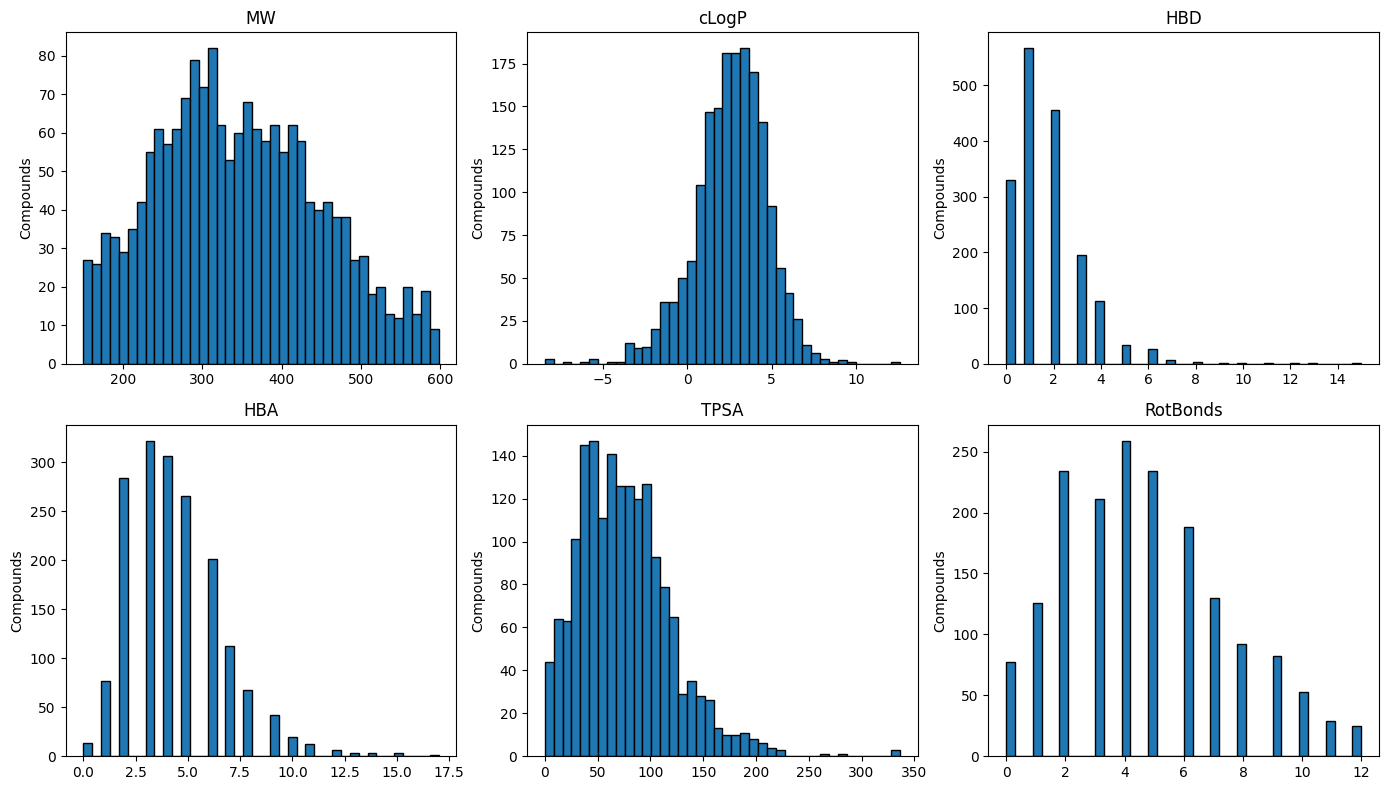

In [ ]:
import matplotlib.pyplot as plt

# Elements typical of organic drugs; anything else (metals, etc.) is excluded
allowed = {"C","H","N","O","S","P","F","Cl","Br","I"}
has_odd_element = library_clean["ROMol"].apply(lambda m: any(a.GetSymbol() not in allowed for a in m.GetAtoms()))

mask = (
    library_clean["MW"].between(150, 600)
    & (library_clean["RotBonds"] <= 12)
    & (library_clean["HeavyAtoms"] >= 10)
    & ~has_odd_element
)

print(f"Removed by property filter: {(~mask).sum()}")
print(f"  odd elements: {has_odd_element.sum()}")
print(f"  MW outside 150-600: {(~library_clean['MW'].between(150, 600)).sum()}")
library_final = library_clean[mask].reset_index(drop=True)
print(f"Final library for docking: {len(library_final)}")

cols = ["MW", "cLogP", "HBD", "HBA", "TPSA", "RotBonds"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, cols):
    ax.hist(library_final[c], bins=40, edgecolor="black")
    ax.set_title(c); ax.set_ylabel("Compounds")
plt.tight_layout()
plt.savefig("library_descriptors.png", dpi=200)
plt.show()

In [ ]:
  library_final[library_final["name"].str.contains("MOMELOTINIB|GILTERITINIB|INFIGRATINIB|OLMUTINIB")][["ID","name","MW"]]

,ID,name,MW
1125,CHEMBL1078178,MOMELOTINIB,414.469
1447,CHEMBL1834657,INFIGRATINIB PHOSPHATE,560.486
1624,CHEMBL3301603,GILTERITINIB FUMARATE,552.724
1662,CHEMBL3786343,OLMUTINIB,486.601


## 3.1. Excluding Known CDK2 Binders
Identify approved drugs with documented CDK2 activity before screening.


In [ ]:
!pip install chembl_webresource_client
import pandas as pd
from chembl_webresource_client.new_client import new_client

res = new_client.activity.filter(
    target_chembl_id="CHEMBL301",              # CDK2; confirm on ChEMBL that this is human CDK2
    standard_type__in=["IC50", "Ki", "Kd"],
    standard_units="nM",
).only(["molecule_chembl_id", "parent_molecule_chembl_id", "standard_type", "standard_value"])
cdk2 = pd.DataFrame(res)
cdk2["standard_value"] = pd.to_numeric(cdk2["standard_value"], errors="coerce")
cdk2 = cdk2.dropna(subset=["standard_value"])
print(f"{len(cdk2)} activity records, {cdk2['molecule_chembl_id'].nunique()} compounds")

# Cutoff sensitivity: how many library drugs are flagged at each threshold?
def flagged(cutoff_nM):
    hits = cdk2[cdk2["standard_value"] <= cutoff_nM]
    ids = set(hits["molecule_chembl_id"]) | set(hits["parent_molecule_chembl_id"].dropna())
    return library_final["ID"].isin(ids)

for c in [1000, 10000, 100000]:
    print(f"<= {c/1000:g} µM: {flagged(c).sum()} library drugs")

5256 activity records, 4172 compounds
<= 1 µM: 5 library drugs
<= 10 µM: 35 library drugs
<= 100 µM: 59 library drugs


In [ ]:
is_known = flagged(10000)
known_cdk2 = library_final[is_known].reset_index(drop=True)      # controls / ML actives
screen = library_final[~is_known].reset_index(drop=True)         # repurposing screen

print(f"Known CDK2 binders removed: {len(known_cdk2)}")
print(f"Screening library: {len(screen)}")
print(known_cdk2[["ID", "name"]].to_string())

Known CDK2 binders removed: 35
Screening library: 1705
               ID                    name
0       CHEMBL535               SUNITINIB
1       CHEMBL553               ERLOTINIB
2       CHEMBL554               LAPATINIB
3     CHEMBL24828              VANDETANIB
4    CHEMBL288441               BOSUTINIB
5       CHEMBL939               GEFITINIB
6       CHEMBL941                IMATINIB
7      CHEMBL1336               SORAFENIB
8    CHEMBL180022               NERATINIB
9    CHEMBL189963             PALBOCICLIB
10     CHEMBL1421     DASATINIB ANHYDROUS
11   CHEMBL221959             TOFACITINIB
12   CHEMBL255863               NILOTINIB
13   CHEMBL477772               PAZOPANIB
14   CHEMBL502835              NINTEDANIB
15   CHEMBL576982             QUIZARTINIB
16   CHEMBL601719              CRIZOTINIB
17   CHEMBL608533             MIDOSTAURIN
18  CHEMBL1078178             MOMELOTINIB
19  CHEMBL1173655                AFATINIB
20  CHEMBL1173055               RUCAPARIB
21  CHEMBL1287853    

In [ ]:
cdk_names = ["PALBOCICLIB","RIBOCICLIB","ABEMACICLIB","TRILACICLIB","ALVOCIDIB","FLAVOPIRIDOL",
             "ROSCOVITINE","SELICICLIB","DINACICLIB","STAUROSPORINE","MOMELOTINIB"]
mask = screen["name"].str.upper().str.contains("|".join(cdk_names), na=False)
print(screen.loc[mask, ["ID", "name"]])

                 ID        name
1605  CHEMBL3545110  RIBOCICLIB


In [ ]:
cdk2_full = pd.read_csv("/content/drive/MyDrive/cdk2_activities.csv")
cdk2_full["pchembl_value"] = pd.to_numeric(cdk2_full["pchembl_value"], errors="coerce")
hits = cdk2_full[cdk2_full["pchembl_value"] >= 5]     # pChEMBL >= 5 means potency <= 10 µM
known_ids = set(hits["molecule_chembl_id"]) | set(hits["parent_molecule_chembl_id"].dropna())

is_known_full = library_final["ID"].isin(known_ids)
print("Flagged with full dataset:", is_known_full.sum(), "| earlier method:", is_known.sum())
print(library_final.loc[is_known_full & ~is_known, ["ID", "name"]].to_string())   # newly caught

cdk_names = ["PALBOCICLIB","RIBOCICLIB","ABEMACICLIB","TRILACICLIB","ALVOCIDIB",
             "FLAVOPIRIDOL","ROSCOVITINE","SELICICLIB","DINACICLIB","STAUROSPORINE"]
name_hit = library_final["name"].str.upper().str.contains("|".join(cdk_names), na=False)

is_known_all = is_known | is_known_full | name_hit
known_cdk2 = library_final[is_known_all].reset_index(drop=True)
screen = library_final[~is_known_all].reset_index(drop=True)

print(f"Known CDK2 binders removed: {len(known_cdk2)}")
print(f"Screening library: {len(screen)}")
print(screen[screen['name'].str.contains('MOMELOTINIB|GILTERITINIB|INFIGRATINIB|OLMUTINIB')][["ID","name"]])

screen[["ID","name","canonical_smiles"]].to_csv("/content/drive/MyDrive/screen.csv", index=False)
known_cdk2[["ID","name","canonical_smiles"]].to_csv("/content/drive/MyDrive/known_cdk2.csv", index=False)

Flagged with full dataset: 9 | earlier method: 35
Empty DataFrame
Columns: [ID, name]
Index: []
Known CDK2 binders removed: 36
Screening library: 1704
                 ID                   name
1593  CHEMBL3301603  GILTERITINIB FUMARATE
1627  CHEMBL3786343              OLMUTINIB


In [ ]:
cdk2_full["standard_value"] = pd.to_numeric(cdk2_full["standard_value"], errors="coerce")

def known_binders(cutoff_nM):
    pot = cdk2_full[
        cdk2_full["standard_type"].isin(["IC50", "Ki", "Kd"])
        & (cdk2_full["standard_units"] == "nM")
        & cdk2_full["standard_relation"].isin(["=", "<", "<="])     # exclude "> 10000" etc.
        & (cdk2_full["standard_value"] <= cutoff_nM)
    ]
    ids = set(pot["molecule_chembl_id"]) | set(pot["parent_molecule_chembl_id"].dropna())
    return library_final["ID"].isin(ids)

for c in [1000, 10000, 100000]:
    print(f"<= {c/1000:g} µM: {known_binders(c).sum()} library drugs")

is_known_fix = known_binders(10000) | is_known_full          # is_known_full is the pChEMBL >= 5 flag
name_hit = library_final["name"].str.upper().str.contains("|".join(cdk_names), na=False)
is_known_all = is_known_fix | name_hit

known_cdk2 = library_final[is_known_all].reset_index(drop=True)
screen = library_final[~is_known_all].reset_index(drop=True)
print(f"Known CDK2 binders removed: {len(known_cdk2)}  |  Screening library: {len(screen)}")
print(known_cdk2[["ID", "name"]].to_string())

# Confirm the wrongly removed drugs were recorded as inactive
restored = library_final.loc[is_known & ~is_known_all, ["ID", "name"]]
ck = cdk2_full[cdk2_full["molecule_chembl_id"].isin(restored["ID"])]
print("\nPreviously removed, now restored:", len(restored))
print(ck[["molecule_chembl_id", "standard_type", "standard_relation", "standard_value"]].head(15).to_string())

<= 1 µM: 4 library drugs
<= 10 µM: 9 library drugs
<= 100 µM: 11 library drugs
Known CDK2 binders removed: 10  |  Screening library: 1730
              ID         name
0      CHEMBL553    ERLOTINIB
1     CHEMBL1336    SORAFENIB
2   CHEMBL189963  PALBOCICLIB
3   CHEMBL502835   NINTEDANIB
4  CHEMBL1078178  MOMELOTINIB
5  CHEMBL2028663   DABRAFENIB
6  CHEMBL2403108    CERITINIB
7  CHEMBL3301610  ABEMACICLIB
8  CHEMBL3545110   RIBOCICLIB
9  CHEMBL3894860  TRILACICLIB

Previously removed, now restored: 26
     molecule_chembl_id standard_type standard_relation  standard_value
745           CHEMBL554            Kd               NaN             NaN
748           CHEMBL535            Kd               NaN             NaN
760           CHEMBL941            Kd               NaN             NaN
761           CHEMBL939            Kd               NaN             NaN
763         CHEMBL24828            Kd               NaN             NaN
1949       CHEMBL221959          IC50                 >       

In [ ]:
screen[["ID","name","canonical_smiles"]].to_csv("/content/drive/MyDrive/screen.csv", index=False)
known_cdk2[["ID","name","canonical_smiles"]].to_csv("/content/drive/MyDrive/known_cdk2.csv", index=False)
print(len(screen), len(known_cdk2))

1730 10


## 3.2. Library Property Comparison (Supplementary Analysis)
Compare molecular properties of the screening library and known CDK2 actives. This cell is retained in its original execution position to avoid disrupting dependencies.


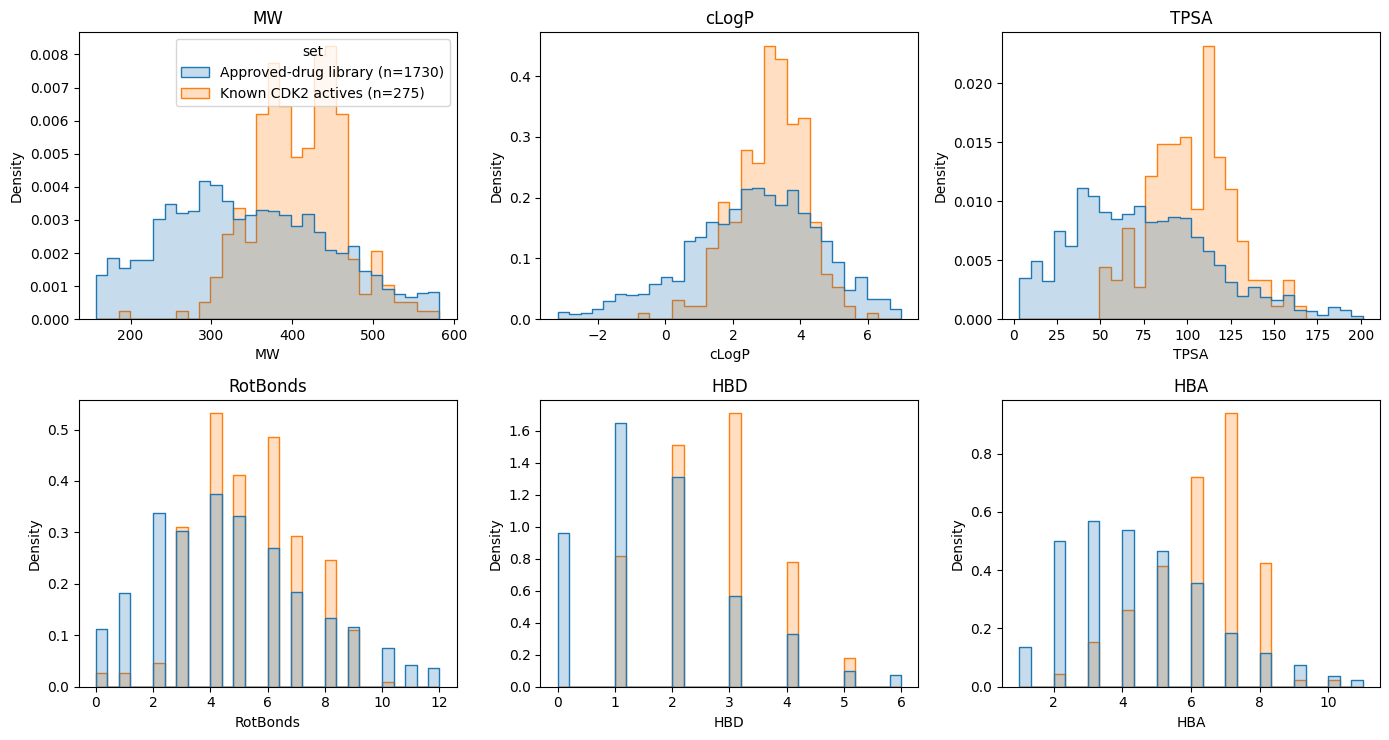

set       Approved-drug library (n=1730)  Known CDK2 actives (n=275)
MW                                 337.8                       406.5
cLogP                                2.7                         3.2
TPSA                                71.5                       103.1
RotBonds                             4.0                         5.0
HBD                                  1.0                         3.0
HBA                                  4.0                         6.0


In [ ]:
import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["MW", "cLogP", "TPSA", "RotBonds", "HBD", "HBA"]

def props(smiles_list):
    rows = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        if m is None:
            rows.append([np.nan] * len(cols)); continue
        rows.append([Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
                     Lipinski.NumRotatableBonds(m), Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m)])
    return pd.DataFrame(rows, columns=cols)

lib = props(screen.canonical_smiles);  lib["set"] = f"Approved-drug library (n={len(lib)})"
act = props(actives.smiles);           act["set"] = f"Known CDK2 actives (n={len(act)})"
df = pd.concat([lib, act], ignore_index=True).dropna()

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, c in zip(axes.flat, cols):
    lo, hi = df[c].quantile([0.01, 0.99])
    sns.histplot(data=df, x=c, hue="set", stat="density", common_norm=False, element="step",
                 bins=30, binrange=(lo, hi), ax=ax, legend=(c == "MW"))
    ax.set_title(c)
plt.tight_layout()
plt.savefig("library_vs_actives_properties.png", dpi=200, bbox_inches="tight")
plt.show()

print(df.groupby("set")[cols].median().round(1).T)

## 3.3. Known-Binder Audit (Supplementary Analysis)
Summarize potency thresholds and known-drug exclusions.


In [ ]:
import pandas as pd, numpy as np

root = "/content/drive/MyDrive/"
screen     = pd.read_csv(root + "screen.csv")
known_cdk2 = pd.read_csv(root + "known_cdk2.csv")
cdk2_full  = pd.read_csv(root + "cdk2_activities.csv")

lib_ids = set(screen["ID"]) | set(known_cdk2["ID"])          # the 1,740 post-filter library
print(len(lib_ids), "library drugs (expect 1740)")

# --- same potency rule as known_binders() ---
cdk2_full["standard_value"] = pd.to_numeric(cdk2_full["standard_value"], errors="coerce")
cdk2_full["pchembl_value"]  = pd.to_numeric(cdk2_full["pchembl_value"],  errors="coerce")

def by_id(df):
    """One row per (library ID, record), matching on molecule ID or parent ID."""
    a = df.assign(ID=df["molecule_chembl_id"])
    b = df.dropna(subset=["parent_molecule_chembl_id"]).assign(ID=lambda d: d["parent_molecule_chembl_id"])
    out = pd.concat([a, b]).drop_duplicates()
    return out[out["ID"].isin(lib_ids)]

pot = by_id(cdk2_full[
    cdk2_full["standard_type"].isin(["IC50", "Ki", "Kd"])
    & (cdk2_full["standard_units"] == "nM")
    & cdk2_full["standard_relation"].isin(["=", "<", "<="])
].dropna(subset=["standard_value"]))

# --- sensitivity counts (should reproduce 4 / 9 / 11) ---
for c in [1000, 10000, 100000]:
    print(f"<= {c/1000:g} µM: {pot.loc[pot.standard_value <= c, 'ID'].nunique()} library drugs")

# --- table for the drugs actually removed ---
best = (pot.sort_values("standard_value").groupby("ID")
           .agg(best_nM=("standard_value", "min"),
                assay=("standard_type", "first"),      # assay type of the best value
                n_records=("standard_value", "size")))
pc = by_id(cdk2_full.dropna(subset=["pchembl_value"])).groupby("ID")["pchembl_value"].max().rename("best_pChEMBL")

tbl = known_cdk2[["ID", "name"]].merge(best, on="ID", how="left").merge(pc, on="ID", how="left")
tbl["Best CDK2 potency (µM)"] = (tbl["best_nM"] / 1000).round(2)
tbl["Why removed"] = np.select(
    [tbl.best_nM <= 10000, tbl.best_pChEMBL >= 5],
    ["IC50/Ki/Kd ≤ 10 µM", "pChEMBL ≥ 5 (other assay type)"],
    default="Name list (known CDK inhibitor)")
tbl = tbl.sort_values("best_nM", na_position="last").reset_index(drop=True)
print(len(tbl), "drugs removed")
tbl[["name", "Best CDK2 potency (µM)", "assay", "n_records", "Why removed"]]

1740 library drugs (expect 1740)
<= 1 µM: 4 library drugs
<= 10 µM: 9 library drugs
<= 100 µM: 11 library drugs
10 drugs removed


,name,Best CDK2 potency (µM),assay,n_records,Why removed
0,TRILACICLIB,0.00,IC50,4,IC50/Ki/Kd ≤ 10 µM
1,PALBOCICLIB,0.01,IC50,2,IC50/Ki/Kd ≤ 10 µM
2,DABRAFENIB,0.02,Kd,1,IC50/Ki/Kd ≤ 10 µM
3,ABEMACICLIB,0.05,IC50,5,IC50/Ki/Kd ≤ 10 µM
4,ERLOTINIB,1.14,IC50,2,IC50/Ki/Kd ≤ 10 µM
5,NINTEDANIB,1.40,Kd,1,IC50/Ki/Kd ≤ 10 µM
6,MOMELOTINIB,2.11,Kd,1,IC50/Ki/Kd ≤ 10 µM
7,CERITINIB,3.97,IC50,1,IC50/Ki/Kd ≤ 10 µM
8,SORAFENIB,8.70,Kd,1,IC50/Ki/Kd ≤ 10 µM
9,RIBOCICLIB,76.00,IC50,1,Name list (known CDK inhibitor)


# 4. CDK2 Crystal Structure and Binding Site (PDB 1H01)
Inspect FAL and the Leu83 hinge region used for docking evaluation.


In [ ]:
from pymol import cmd

cmd.reinitialize()
cmd.fetch("1H01")

print("Chains:", cmd.get_chains("1H01"))
stored = []
cmd.iterate("organic", "stored.append((resn, chain, resi))", space={"stored": stored})
print("Small molecules:", sorted(set(stored)))

cmd.select("1H01-ligand", "resn FAL and chain A")
cmd.select("1H01-receptor", "polymer.protein and chain A")
print("Ligand atoms:", cmd.count_atoms("1H01-ligand"), "| Protein atoms:", cmd.count_atoms("1H01-receptor"))

cmd.save("1H01-ligand.pdb", "1H01-ligand")
cmd.save("1H01-receptor.pdb", "1H01-receptor")

Chains: ['A']
Small molecules: [('FAL', 'A', '301'), ('FBL', 'A', '302'), ('GOL', 'A', '299'), ('GOL', 'A', '300')]
Ligand atoms: 30 | Protein atoms: 2357


In [ ]:
!cp 1H01-ligand.pdb 1H01-receptor.pdb /content/drive/MyDrive/

Formula: C21H23Cl2N5O2 (expected C21H23Cl2N5O2)
Stereo: [(4, 'R')] (expected R)


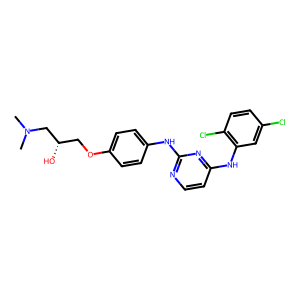

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.rdMolDescriptors import CalcMolFormula

# FAL = (2R)-1-[4-({4-[(2,5-dichlorophenyl)amino]pyrimidin-2-yl}amino)phenoxy]-3-(dimethylamino)propan-2-ol
# Compare against the SMILES on https://www.rcsb.org/ligand/FAL
fal_smiles = "CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1"

tmpl = Chem.MolFromSmiles(fal_smiles)
print("Formula:", CalcMolFormula(tmpl), "(expected C21H23Cl2N5O2)")
print("Stereo:", Chem.FindMolChiralCenters(tmpl, useLegacyImplementation=False), "(expected R)")
display(Draw.MolToImage(tmpl, size=(300, 300)))

lig = Chem.AddHs(tmpl, addCoords=True)
AllChem.EmbedMolecule(lig, randomSeed=42)
AllChem.MMFFOptimizeMolecule(lig)

# view the 3D result
mblock = Chem.MolToMolBlock(lig)
view = py3Dmol.view(data=mblock, style={"stick": {}, "sphere": {"scale": 0.3}})
view.zoomTo()
view.show()

w = Chem.SDWriter("newligand_1H01.sdf"); w.write(lig); w.close()

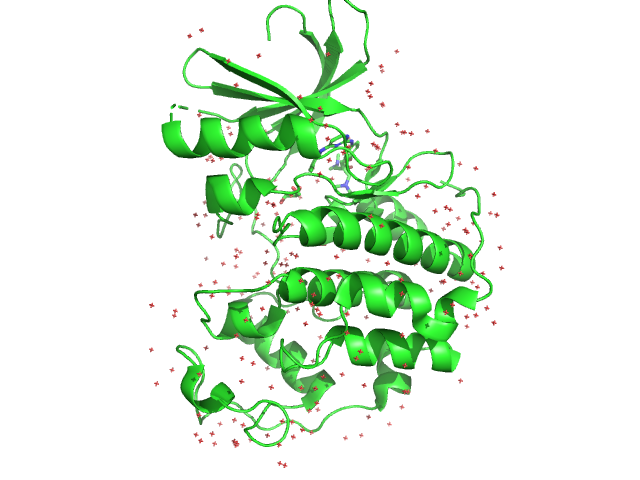

In [ ]:
from pymol import cmd
from IPython.display import Image
import os
os.environ['PYMOL_PATH'] = os.path.join(os.getcwd())
cmd.reinitialize()
cmd.fetch("1H01")
cmd.orient("1H01")
cmd.rotate("z","270")
cmd.png("image.png")
Image(filename = "image.png", unconfined=True)

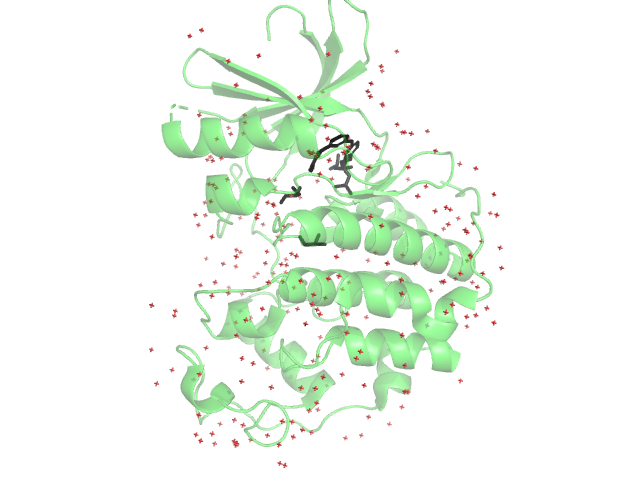

In [ ]:
cmd.color("black","organic")
cmd.set("cartoon_transparency",0.5)
cmd.png("image.png")
Image(filename = "image.png", unconfined=True)

In [ ]:
cmd.select("het", "organic")   # all small molecules
print(cmd.count_atoms("het"))
stored = []
cmd.iterate("het", "stored.append((resn, chain, resi))", space={"stored": stored})
print(sorted(set(stored)))

327
[('FAL', 'A', '301'), ('FBL', 'A', '302'), ('GOL', 'A', '299'), ('GOL', 'A', '300'), ('HOH', 'A', '2001'), ('HOH', 'A', '2002'), ('HOH', 'A', '2003'), ('HOH', 'A', '2004'), ('HOH', 'A', '2005'), ('HOH', 'A', '2006'), ('HOH', 'A', '2007'), ('HOH', 'A', '2008'), ('HOH', 'A', '2009'), ('HOH', 'A', '2010'), ('HOH', 'A', '2011'), ('HOH', 'A', '2012'), ('HOH', 'A', '2013'), ('HOH', 'A', '2014'), ('HOH', 'A', '2015'), ('HOH', 'A', '2016'), ('HOH', 'A', '2017'), ('HOH', 'A', '2018'), ('HOH', 'A', '2019'), ('HOH', 'A', '2020'), ('HOH', 'A', '2021'), ('HOH', 'A', '2022'), ('HOH', 'A', '2023'), ('HOH', 'A', '2024'), ('HOH', 'A', '2025'), ('HOH', 'A', '2026'), ('HOH', 'A', '2027'), ('HOH', 'A', '2028'), ('HOH', 'A', '2029'), ('HOH', 'A', '2030'), ('HOH', 'A', '2031'), ('HOH', 'A', '2032'), ('HOH', 'A', '2033'), ('HOH', 'A', '2034'), ('HOH', 'A', '2035'), ('HOH', 'A', '2036'), ('HOH', 'A', '2037'), ('HOH', 'A', '2038'), ('HOH', 'A', '2039'), ('HOH', 'A', '2040'), ('HOH', 'A', '2041'), ('HOH', '

In [ ]:
cmd.select("1H01-ligand", "resn FAL and chain A")
cmd.select("1H01-receptor", "polymer.protein")

cmd.save("1H01-ligand.pdb", "1H01-ligand")
cmd.save("1H01-receptor.pdb", "1H01-receptor")

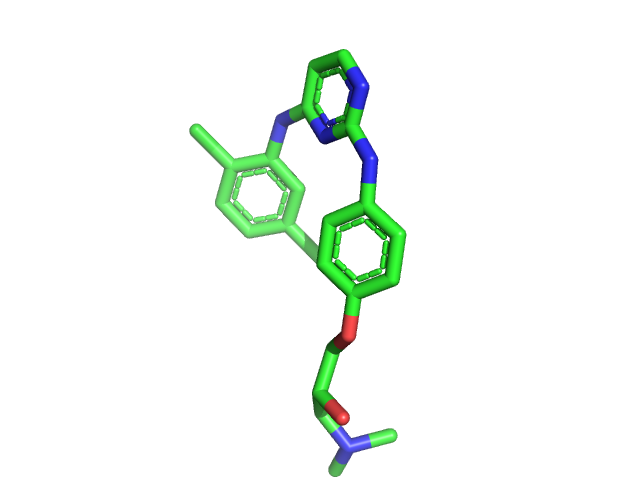

In [ ]:
cmd.reinitialize()
cmd.load("1H01-ligand.pdb")
cmd.png("ligand.png")
Image(filename = "ligand.png", unconfined=True)

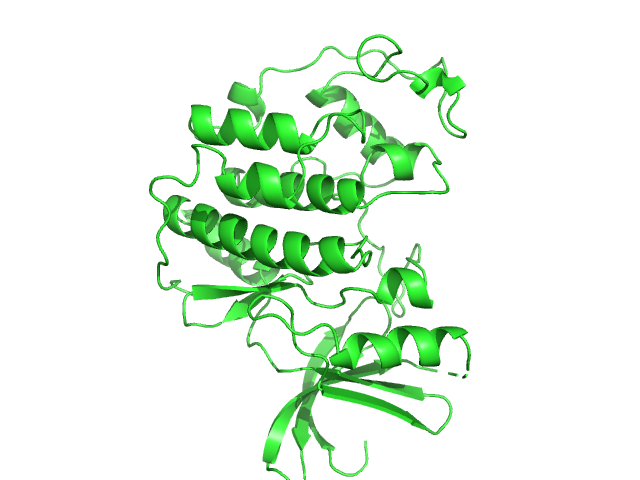

In [ ]:
#Now the receptor
cmd.reinitialize()
cmd.load("1H01-receptor.pdb")
cmd.orient("1H01-receptor")
cmd.rotate("z","270")
cmd.png("receptor.png")
Image(filename = "receptor.png", unconfined=True)

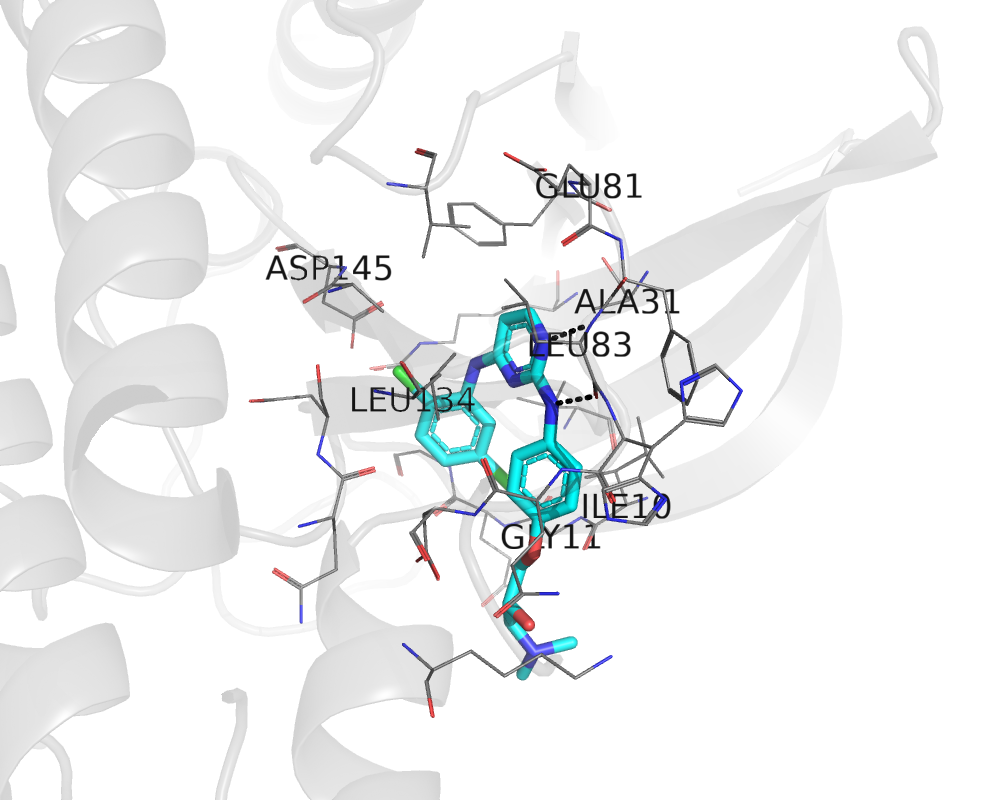

In [ ]:
#reload figure
cmd.reinitialize()
cmd.load("1H01-receptor.pdb")
cmd.load("1H01-ligand.pdb")

cmd.color("grey","1H01-receptor")

#select sphere around the ligand and show the residues
cmd.select("pocketresidues", "byres (all within 5 of 1H01-ligand)&polymer.protein")
cmd.show("line","pocketresidues")
cmd.show("stick","1H01-ligand")
cmd.set("cartoon_transparency", 0.8)
cmd.util.cnc()

#Find hydrogen-bond contacts between the ligand and the pocket, 3.5 A cutoff
cmd.distance("hbonds", "1H01-ligand", "pocketresidues", 3.5, mode=2)
cmd.set("dash_color", "black")
cmd.hide("labels", "hbonds")

#Label the pocket residues that make the contacts
cmd.select("hbond_residues", "byres (pocketresidues within 3.5 of 1H01-ligand)")
cmd.label("hbond_residues and name CA", "resn+resi")
cmd.set("label_size", 20)
cmd.set("label_color", "black")
cmd.set("label_position", (0, 0, 2))

cmd.zoom("pocketresidues", 4)
cmd.png("1H01-pocket.png", width=1000, height=800, dpi=200, ray=1)
Image(filename = "1H01-pocket.png", unconfined=True)

In [ ]:
cmd.select("lig_polar", "1H01-ligand and (elem N or elem O)")
cmd.select("rec_polar", "pocketresidues and (elem N or elem O)")
cmd.iterate("(rec_polar within 3.5 of lig_polar)", "print(resn, resi, name)")

LEU 83 N
LEU 83 O


2

In [ ]:
from pymol import cmd

cmd.reinitialize()
cmd.load("1H01-receptor.pdb")
cmd.load("1H01-ligand.pdb")

# Pocket residues: same selection as the hydrogen-bond cell
cmd.select("pocketresidues", "byres (all within 5 of 1H01-ligand)&polymer.protein")

pocket = []
cmd.iterate("pocketresidues and name CA", "pocket.append((int(resi), resn))", space={"pocket": pocket})
pocket = sorted(pocket)

print(f"{len(pocket)} residues have an atom within 5 Å of the cognate ligand FAL")
print(", ".join(f"{resn.capitalize()}{resi}" for resi, resn in pocket))

21 residues have an atom within 5 Å of the cognate ligand FAL
Ile10, Gly11, Glu12, Gly13, Val18, Ala31, Kcx33, Val64, Phe80, Glu81, Phe82, Leu83, His84, Gln85, Asp86, Lys89, Gln131, Asn132, Leu134, Ala144, Asp145


# 5. Docking Method Validation
Redock the cognate FAL ligand, assess pose recovery, and test whether docking scores discriminate CDK2 actives from inactives.


In [ ]:
!wget https://sourceforge.net/projects/smina/files/smina.static/download -O smina.static
!chmod u+x smina.static
!./smina.static -r 1H01-receptor.pdb -l newligand_1H01.sdf --autobox_ligand 1H01-ligand.pdb -o 1H01-ligand-poses.sdf

--2026-10-23 21:46:17--  https://sourceforge.net/projects/smina/files/smina.static/download
Resolving sourceforge.net (sourceforge.net)... 104.18.12.149, 104.18.13.149, 2606:4700::6812:d95, ...
Connecting to sourceforge.net (sourceforge.net)|104.18.12.149|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://downloads.sourceforge.net/project/smina/smina.static?ts=gAAAAABq29Wp9Ub31f2XQYsU-1W-hiMaAs5hubRSOTejh6WSGUWX_Zb4pzuoV6KFJNGIie3MWiUNn7T7N-Ej6ENRDaAmfn7CQw%3D%3D&use_mirror=cfhcable&r= [following]
--2026-10-23 21:46:17--  https://downloads.sourceforge.net/project/smina/smina.static?ts=gAAAAABq29Wp9Ub31f2XQYsU-1W-hiMaAs5hubRSOTejh6WSGUWX_Zb4pzuoV6KFJNGIie3MWiUNn7T7N-Ej6ENRDaAmfn7CQw%3D%3D&use_mirror=cfhcable&r=
Resolving downloads.sourceforge.net (downloads.sourceforge.net)... 104.18.12.149, 104.18.13.149, 2606:4700::6812:d95, ...
Connecting to downloads.sourceforge.net (downloads.sourceforge.net)|104.18.12.149|:443... connected.
HTTP request sent, aw

In [ ]:
!./smina.static -r 1H01-receptor.pdb -l newligand_1H01.sdf --autobox_ligand 1H01-ligand.pdb -o ref_exh1.sdf --seed 1 --exhaustiveness 1 --num_modes 1 -q
from rdkit.Chem import PandasTools
ref = PandasTools.LoadSDF("ref_exh1.sdf")
ref_score = float(ref["minimizedAffinity"].iloc[0])
print("Cognate (FAL) reference at exhaustiveness 1:", ref_score)

*** Open Babel Warning  in Init
  Unable to open data file 'space-groups.txt'
*** Open Babel Warning  in Init
  Cannot initialize database 'space-groups.txt' which may cause further errors.

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Refine time 12.3344
Loop time 12.9007
Cognate (FAL) reference at exhaustiveness 1: -9.28788


,minimizedAffinity,ID,ROMol
0,-9.61507,,
1,-9.59135,,
2,-9.36541,,
3,-9.30884,,
4,-8.84710,,
5,-8.81313,,
6,-8.76545,,
7,-8.70872,,
8,-8.53801,,

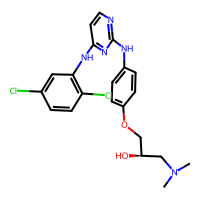
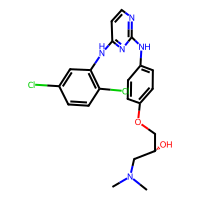
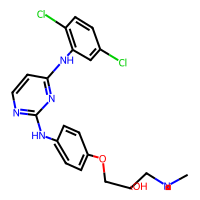
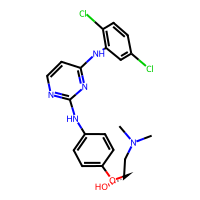
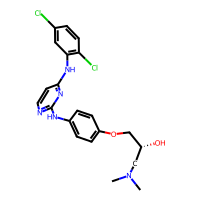
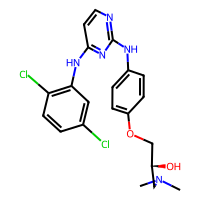
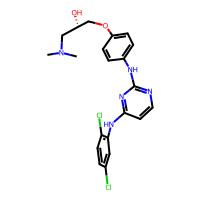
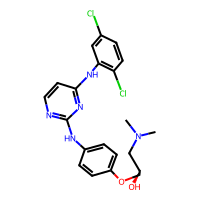
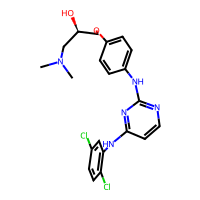

In [ ]:
from rdkit.Chem import PandasTools
dockedposes = PandasTools.LoadSDF("1H01-poses.sdf")
dockedposes

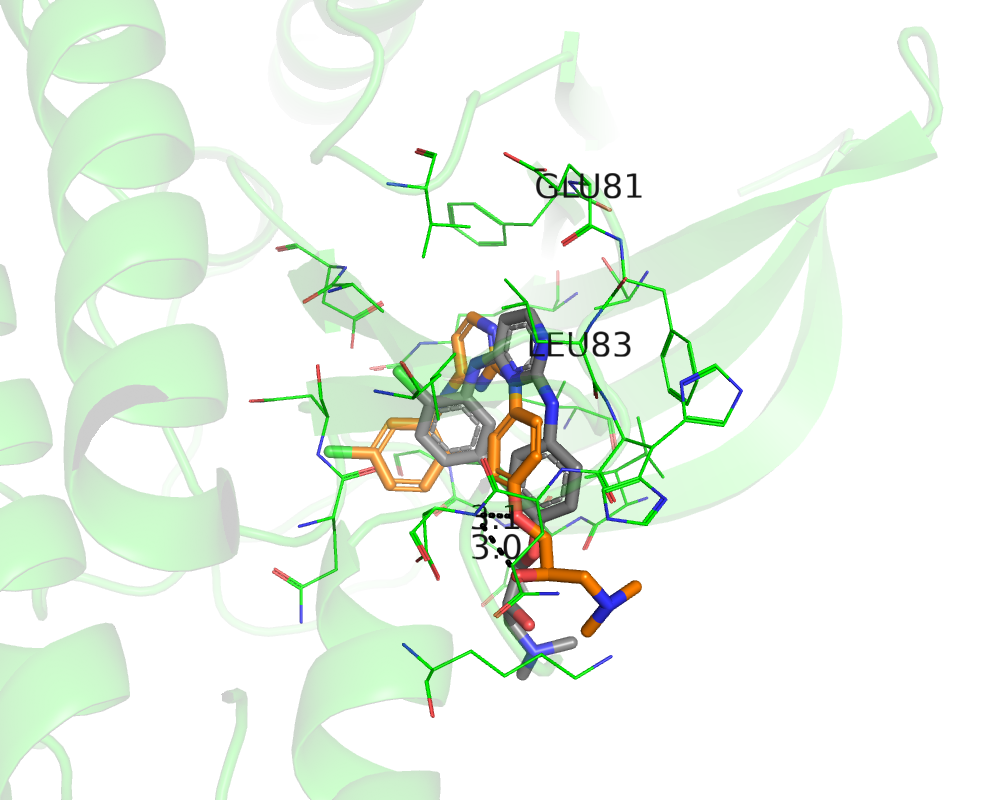

In [ ]:
from pymol import cmd
from IPython.display import Image

cmd.reinitialize()
cmd.load("1H01-receptor.pdb", "receptor")
cmd.load("1H01-ligand.pdb", "crystal")
cmd.load("1H01-poses.sdf", "poses")
cmd.create("pose1", "poses", 1, 1)      # top-scoring pose only
cmd.delete("poses")

cmd.color("green", "receptor")
cmd.color("grey", "crystal")
cmd.color("orange", "pose1")
cmd.select("pocketresidues", "byres (all within 5 of crystal) & polymer.protein")
cmd.show("line", "pocketresidues")
cmd.show("stick", "crystal or pose1")
cmd.set("cartoon_transparency", 0.8)
cmd.set("ray_shadow", 0)
cmd.util.cnc()

# H-bonds from the docked pose to the pocket (3.5 Å cutoff)
cmd.distance("hb_dock", "pose1", "pocketresidues", 3.5, mode=2)
cmd.set("dash_color", "black")
cmd.label("pocketresidues and resi 81+83 and name CA", "resn+resi")
cmd.set("label_size", 20); cmd.set("label_color", "black")

cmd.zoom("pocketresidues", 4)
cmd.png("1H01-redock.png", width=1000, height=800, dpi=200, ray=1)
Image(filename="1H01-redock.png", unconfined=True)

In [ ]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

# --- crystal ligand with correct bond orders (from the same SMILES used for docking) ---
fal_smiles = "CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1"
tmpl = Chem.MolFromSmiles(fal_smiles)
print("Stereo:", Chem.FindMolChiralCenters(tmpl, useLegacyImplementation=False), "(expected R)")
crystal = AllChem.AssignBondOrdersFromTemplate(
    tmpl, Chem.MolFromPDBFile("1H01-ligand.pdb", removeHs=True))

# --- hinge atoms from the receptor ---
rec = Chem.MolFromPDBFile("1H01-receptor.pdb", removeHs=False, sanitize=False)
rc = rec.GetConformer()
want = {(81, "O"): "Glu81 O", (83, "N"): "Leu83 N", (83, "O"): "Leu83 O"}
hinge = {}
for a in rec.GetAtoms():
    info = a.GetPDBResidueInfo()
    key = (info.GetResidueNumber(), info.GetName().strip())
    if info.GetChainId() == "A" and key in want:
        hinge[want[key]] = np.array(rc.GetAtomPosition(a.GetIdx()))
print("Hinge atoms found:", list(hinge))

def contacts(mol):
    c = mol.GetConformer()
    polar = [np.array(c.GetAtomPosition(a.GetIdx())) for a in mol.GetAtoms()
             if a.GetSymbol() in ("N", "O")]
    return {k: min(np.linalg.norm(v - p) for p in polar) for k, v in hinge.items()}

# --- poses ---
poses = list(Chem.SDMolSupplier("1H01-poses.sdf", removeHs=True))

print("\nPose | Score | RMSD to crystal | hinge ≤3.5 Å | distances (Å)")
d = contacts(crystal)
print("cryst|   -   |       0.00      | " + f"{sum(v <= 3.5 for v in d.values())}/3          | "
      + ", ".join(f"{k} {v:.2f}" for k, v in d.items()))
for i, p in enumerate(poses, 1):
    d = contacts(p)
    n = sum(v <= 3.5 for v in d.values())
    print(f"{i:>4} | {float(p.GetProp('minimizedAffinity')):>5.1f} | "
          f"{rdMolAlign.CalcRMS(p, crystal):>9.2f}       | {n}/3          | "
          + ", ".join(f"{k} {v:.2f}" for k, v in d.items()))

Stereo: [(4, 'R')] (expected R)
Hinge atoms found: ['Glu81 O', 'Leu83 N', 'Leu83 O']

Pose | Score | RMSD to crystal | hinge ≤3.5 Å | distances (Å)
cryst|   -   |       0.00      | 2/3          | Glu81 O 3.73, Leu83 N 3.13, Leu83 O 2.69
   1 |  -9.6 |      3.61       | 0/3          | Glu81 O 5.20, Leu83 N 5.43, Leu83 O 5.07
   2 |  -9.6 |      3.19       | 0/3          | Glu81 O 5.19, Leu83 N 5.44, Leu83 O 4.93
   3 |  -9.4 |      4.96       | 0/3          | Glu81 O 7.56, Leu83 N 7.92, Leu83 O 5.54
   4 |  -9.3 |      5.24       | 0/3          | Glu81 O 7.44, Leu83 N 8.19, Leu83 O 5.86
   5 |  -8.8 |      5.05       | 0/3          | Glu81 O 7.98, Leu83 N 8.05, Leu83 O 5.47
   6 |  -8.8 |      2.87       | 0/3          | Glu81 O 5.45, Leu83 N 5.56, Leu83 O 5.08
   7 |  -8.8 |      7.97       | 1/3          | Glu81 O 6.12, Leu83 N 5.39, Leu83 O 3.19
   8 |  -8.7 |      5.79       | 0/3          | Glu81 O 9.33, Leu83 N 7.87, Leu83 O 5.61
   9 |  -8.5 |      7.60       | 1/3          | Glu

In [ ]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

# CDK2 activity data downloaded earlier (CHEMBL301)
cdk2_full = pd.read_csv("/content/drive/MyDrive/cdk2_activities.csv")

# Canonicalize SMILES before doing anything else
def canonicalize(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

cdk2_full['pchembl_value'] = pd.to_numeric(cdk2_full['pchembl_value'], errors='coerce')
cdk2_full['standard_value'] = pd.to_numeric(cdk2_full['standard_value'], errors='coerce')

# the cognate ligand (FAL), used for the similarity column only
cognate = pd.DataFrame({"canonical_smiles": ["CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1"]})

# ---- actives: pChEMBL > 8 ----
actives = cdk2_full.loc[cdk2_full['pchembl_value'] > 8, ['canonical_smiles']].copy()
actives = actives.dropna(subset=['canonical_smiles'])
actives['canonical_smiles'] = actives['canonical_smiles'].apply(canonicalize)
actives = actives.dropna(subset=['canonical_smiles'])
actives = actives.drop_duplicates(subset='canonical_smiles', keep="first")

# ---- inactives: > 10 uM ----
inactives = cdk2_full.loc[
    (cdk2_full['standard_type'].isin(['IC50', 'Ki', 'Kd'])) &
    (cdk2_full['standard_units'] == 'nM') &
    (cdk2_full['standard_value'] > 10000) &
    (cdk2_full['standard_relation'].isin(['=', '>', '>='])),
    ['canonical_smiles']].copy()
inactives['canonical_smiles'] = inactives['canonical_smiles'].apply(canonicalize)
inactives = inactives.dropna(subset=['canonical_smiles'])
inactives = inactives.drop_duplicates(subset='canonical_smiles', keep="first")

# remove any compound that ended up in both groups
both = set(actives['canonical_smiles']) & set(inactives['canonical_smiles'])
actives = actives[~actives['canonical_smiles'].isin(both)]
inactives = inactives[~inactives['canonical_smiles'].isin(both)]

# ---- similarity to the cognate ligand ----
fpgen = AllChem.GetMorganGenerator()
query = Chem.MolFromSmiles(canonicalize(cognate['canonical_smiles'][0]))
queryfp = fpgen.GetFingerprint(query)

def add_sim(df, label):
    sim = []
    for x in df.canonical_smiles:
        target = Chem.MolFromSmiles(x)
        sim.append(None if target is None else DataStructs.TanimotoSimilarity(fpgen.GetFingerprint(target), queryfp))
    df = df.copy()
    df["Active"] = label
    df["Sim"] = sim
    df = df.rename(columns={'canonical_smiles': 'smiles'})
    return df.sort_values("Sim", ascending=False)

actives = add_sim(actives, "True")
inactives = add_sim(inactives, "False")

print(f"Actives (pChEMBL > 8):    {len(actives)}")
print(f"Inactives (> 10 uM):      {len(inactives)}")
print(f"Removed (in both groups): {len(both)}")
actives

Actives (pChEMBL > 8):    275
Inactives (> 10 uM):      962
Removed (in both groups): 2


,smiles,Active,Sim
2388,Cc1nc2ccccn2c1-c1ccnc(Nc2ccc(OCC(O)CN(C)C)cc2)n1,True,0.423423
351,Cc1ccc(F)c(Nc2ccnc(Nc3ccc(S(N)(=O)=O)cc3)n2)c1,True,0.320755
1729,COc1ccc(Nc2nccc(-c3cnc(C)n3C(C)C)n2)cc1,True,0.252336
1834,Cc1ncc(-c2ccnc(Nc3ccc(C(=O)N(C)C)cc3)n2)n1C(C)C,True,0.228070
1566,CCCS(=O)(=O)c1ccc(Nc2nccc(-c3cnc(C)n3C(C)C)n2)cc1,True,0.222222
...,...,...,...
6840,O=C1Nc2ccc([N+](=O)[O-])cc2/C1=C1/Nc2ccc(O)cc2...,True,0.037594
240,O=C1Nc2ccc(C(=O)O)cc2/C1=C/c1[nH]cc2c1CCOC2=O,True,0.036232
10315,O=C1Nc2ccccc2/C1=C1/Nc2ccccc2C1=O,True,0.035714
225,O=C1Nc2ccc(F)c3c(S[C@H]4CCNC4)cc(-c4ccc[nH]4)c...,True,0.035461


In [ ]:
import numpy as np
from rdkit.Chem import AllChem, PandasTools
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

# random subsample (seed so it's reproducible)
vsmols = pd.concat([actives.sample(50, random_state=42),
                    inactives.sample(100, random_state=42)]).reset_index(drop=True)
vsmols["ID"] = ["Molecule_" + str(i) for i in range(len(vsmols))]

# Convert3D, plus desalting (largest fragment) and a check for failures
def Convert3D(molsmile):
    mol = Chem.MolFromSmiles(molsmile)
    if mol is None:
        return None
    mol = chooser.choose(mol)                        # strip salts
    mol = Chem.AddHs(mol, addCoords=True)
    if AllChem.EmbedMolecule(mol, randomSeed=42) != 0:
        return None
    try:
        AllChem.MMFFOptimizeMolecule(mol)
    except Exception:
        return None
    return mol

vsmols["minim"] = [Convert3D(s) for s in vsmols.smiles]
print("Failed 3D conversion:", vsmols["minim"].isna().sum())
vsmols = vsmols.dropna(subset=["minim"]).reset_index(drop=True)

print(f"Molecules to dock: {len(vsmols)}  "
      f"({(vsmols.Active=='True').sum()} actives, {(vsmols.Active=='False').sum()} inactives)")

PandasTools.WriteSDF(vsmols, out="cdk2_valid.sdf", molColName='minim',
                     idName='ID', properties=None, allNumeric=False, forceV3000=False)

# back up to Drive (the docking step is long)
!cp cdk2_valid.sdf /content/drive/MyDrive/

Failed 3D conversion: 0
Molecules to dock: 150  (50 actives, 100 inactives)


In [ ]:
import time
start = time.time()
!./smina.static -r 1H01-receptor.pdb -l cdk2_valid.sdf --autobox_ligand 1H01-ligand.pdb -o cdk2_valid_out.sdf --exhaustiveness 1 --num_modes 1 -q
print(f"Took {(time.time()-start)/60:.1f} minutes")
!cp cdk2_valid_out.sdf /content/drive/MyDrive/

*** Open Babel Warning  in Init
  Unable to open data file 'space-groups.txt'
*** Open Babel Warning  in Init
  Cannot initialize database 'space-groups.txt' which may cause further errors.

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Refine time 9.8849

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Refine time 7.76221

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Refine time 4.55774

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Refine time 13.35

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|-

In [ ]:
vsresults = PandasTools.LoadSDF("cdk2_valid_out.sdf")

merged = vsmols.merge(vsresults, left_on="ID", right_on="ID")
merged = merged[['ID', 'Active', 'Sim', 'minimizedAffinity']]
merged['minimizedAffinity'] = pd.to_numeric(merged['minimizedAffinity'], errors='coerce')
merged = merged.sort_values('minimizedAffinity', ascending=True)

print(f"Docked and scored: {len(merged)} of {len(vsmols)}")
print(f"Scores missing: {merged['minimizedAffinity'].isna().sum()}")
merged

Docked and scored: 150 of 150
Scores missing: 0


,ID,Active,Sim,minimizedAffinity
61,Molecule_61,False,0.170543,-12.22575
149,Molecule_149,False,0.185185,-11.84225
94,Molecule_94,False,0.136364,-11.69732
60,Molecule_60,False,0.064748,-11.46041
116,Molecule_116,False,0.173913,-11.38045
...,...,...,...,...
114,Molecule_114,False,0.097561,-8.28465
111,Molecule_111,False,0.124138,-8.06716
99,Molecule_99,False,0.100000,-7.64962
56,Molecule_56,False,0.126214,-6.99012


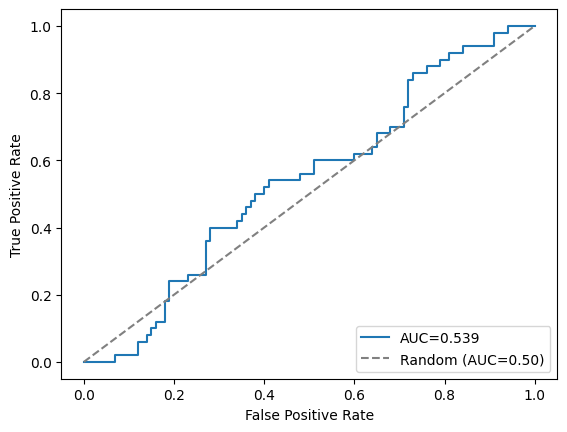

In [ ]:
from sklearn import metrics
import matplotlib.pyplot as plt

merged.replace({"False": 0, "True": 1}, inplace=True)

fpr, tpr, _ = metrics.roc_curve(merged['Active'], -merged['minimizedAffinity'])
auc = metrics.roc_auc_score(merged['Active'], -merged['minimizedAffinity'])

plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label="Random (AUC=0.50)")
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.savefig("cdk2_docking_roc.png", dpi=200, bbox_inches="tight")
plt.show()

# 6. Machine Learning Model Development
Prepare fingerprints and evaluate random, scaffold, and chemical-cluster validation.


In [ ]:
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina

bitgen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
fps = [bitgen.GetFingerprint(m) for m in data.mol]

# Butina clustering: distance = 1 - Tanimoto, threshold 0.6 (i.e. similarity >= 0.4)
dists = []
for i in range(1, len(fps)):
    dists.extend([1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])])
clusters = Butina.ClusterData(dists, len(fps), 0.6, isDistData=True)
cl = np.zeros(len(fps), dtype=int)
for cid, members in enumerate(clusters):
    cl[list(members)] = cid

df_cl = pd.DataFrame({"cl": cl, "y": y})
mixed = (df_cl.groupby("cl").y.nunique() == 2).sum()
print(f"Clusters: {len(clusters)} | clusters with both actives and inactives: {mixed}")

p_clu = cross_val_predict(rf, X, y, cv=GroupKFold(5), groups=cl, method="predict_proba")[:, 1]
print(f"Cluster-split AUC = {metrics.roc_auc_score(y, p_clu):.3f}")

Clusters: 359 | clusters with both actives and inactives: 26
Cluster-split AUC = 0.882


## 6.1. ML Cross-Validation Results
Plot ROC curves for random, scaffold, and cluster splits.


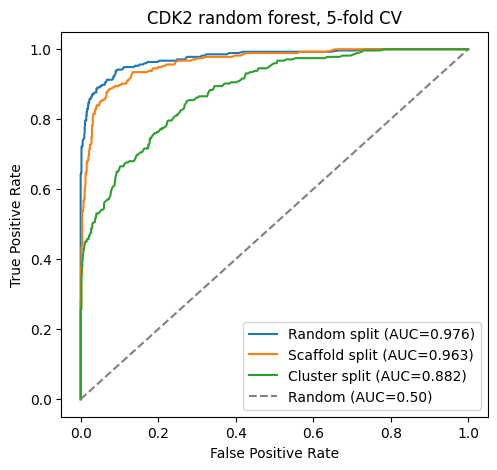

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for p, lab in [(p_rand, "Random split"), (p_scaf, "Scaffold split"), (p_clu, "Cluster split")]:
    fpr, tpr, _ = metrics.roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{lab} (AUC={metrics.roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "--", c="grey", label="Random (AUC=0.50)")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title="CDK2 random forest, 5-fold CV")
ax.legend(loc=4)
plt.savefig("cdk2_ml_roc_all.png", dpi=200, bbox_inches="tight"); plt.show()

## 6.2. Training-Set Leakage Controls
Standardize structures and exclude overlapping drugs from model training.


In [ ]:
from rdkit.Chem.MolStandardize import rdMolStandardize
ch, un = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()

def key(smi):
    m = Chem.MolFromSmiles(smi)
    return None if m is None else Chem.MolToInchiKey(un.uncharge(ch.choose(m)))[:14]

train_keys = {k: lab for k, lab in zip(data.smiles.apply(key), data.y) if k}
screen["key"] = screen.canonical_smiles.apply(key)
overlap = screen[screen.key.isin(train_keys)].copy()
overlap["train_label"] = overlap.key.map(train_keys)
print(len(overlap), "screening drugs also in the training data")
overlap[["ID", "name", "train_label"]]

53 screening drugs also in the training data


,ID,name,train_label
94,CHEMBL61,PODOFILOX,0
101,CHEMBL477,ADENOSINE,0
162,CHEMBL535,SUNITINIB,0
174,CHEMBL554,LAPATINIB,0
319,CHEMBL24828,VANDETANIB,0
417,CHEMBL288441,BOSUTINIB,0
495,CHEMBL939,GEFITINIB,0
499,CHEMBL941,IMATINIB,0
612,CHEMBL1090,VIDARABINE,0
768,CHEMBL180022,NERATINIB,0


In [ ]:
# Training set without the screening drugs that already have a measured CDK2 label
data["key"] = data.smiles.apply(key)
train = data[~data.key.isin(set(screen.key))].reset_index(drop=True)
print(f"Final training set: {len(train)} compounds ({train.y.sum()} actives, {(1-train.y).sum()} inactives); "
      f"{len(data)-len(train)} removed (also in the screening library)")

Xt = np.array([gen.GetCountFingerprintAsNumPy(m) for m in train.mol])
yt = train.y.values
rf_final = RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=42).fit(Xt, yt)

screen["mol"] = screen.canonical_smiles.apply(Chem.MolFromSmiles)
Xs = np.array([gen.GetCountFingerprintAsNumPy(m) for m in screen.mol])
screen["ML_score"] = rf_final.predict_proba(Xs)[:, 1]
screen["has_cdk2_label"] = screen.key.isin(train_keys)     # the 53 drugs with measured CDK2 inactivity

# Candidates come only from drugs with no measured CDK2 data
cand = screen[~screen.has_cdk2_label].sort_values("ML_score", ascending=False).reset_index(drop=True)
held = screen[screen.has_cdk2_label]
print(f"Candidates: {len(cand)} | held-out known inactives: {len(held)}")
print(f"Held-out inactives: median ML score {held.ML_score.median():.2f}, max {held.ML_score.max():.2f}; "
      f"candidates: median {cand.ML_score.median():.2f}, max {cand.ML_score.max():.2f}")

cand[["ID", "name", "canonical_smiles", "ML_score"]].to_csv("/content/drive/MyDrive/CDK2_project/ml_candidates.csv", index=False)
cand[["ID", "name", "ML_score"]].head(25)

Final training set: 1186 compounds (275 actives, 911 inactives); 51 removed (also in the screening library)
Candidates: 1677 | held-out known inactives: 53
Held-out inactives: median ML score 0.12, max 0.52; candidates: median 0.11, max 0.50


,ID,name,ML_score
0,CHEMBL419,MAFENIDE,0.496
1,CHEMBL21,SULFANILAMIDE,0.494
2,CHEMBL328560,SULTHIAME,0.488
3,CHEMBL118,CELECOXIB,0.484
4,CHEMBL1570,SULFOXONE,0.452
5,CHEMBL1200359,SULFAMETER,0.452
6,CHEMBL438,SULFAMERAZINE,0.438
7,CHEMBL1742471,EBROTIDINE,0.430
8,CHEMBL865,VALDECOXIB,0.414
9,CHEMBL409,BICALUTAMIDE,0.412


## 6.3. External Check with Known Approved CDK2 Binders
Assess performance on approved drugs with known CDK2 activity.


In [ ]:
from sklearn import metrics

known_cdk2["key"] = known_cdk2.canonical_smiles.apply(key)
train2 = data[~data.key.isin(set(screen.key) | set(known_cdk2.key))].reset_index(drop=True)
print(f"Training set without the 10 known binders: {len(train2)} ({train2.y.sum()} actives)")

rf2 = RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=42)
rf2.fit(np.array([gen.GetCountFingerprintAsNumPy(m) for m in train2.mol]), train2.y.values)

pool = pd.concat([screen[~screen.has_cdk2_label].assign(group="candidate"),
                  known_cdk2.assign(group="known")], ignore_index=True)
pool["mol"] = pool.canonical_smiles.apply(Chem.MolFromSmiles)
pool["ML_score"] = rf2.predict_proba(np.array([gen.GetCountFingerprintAsNumPy(m) for m in pool.mol]))[:, 1]
pool["rank"] = pool.ML_score.rank(ascending=False).astype(int)

is_known_flag = (pool.group == "known").astype(int)
print(f"AUC, 10 known binders vs {len(pool)-10} candidates: {metrics.roc_auc_score(is_known_flag, pool.ML_score):.3f}")
pool[pool.group == "known"][["name", "ML_score", "rank"]].sort_values("rank")

Training set without the 10 known binders: 1178 (274 actives)
AUC, 10 known binders vs 1677 candidates: 0.651


,name,ML_score,rank
1684,ABEMACICLIB,0.694,1
1686,TRILACICLIB,0.590,2
1683,CERITINIB,0.360,37
1679,PALBOCICLIB,0.234,140
1681,MOMELOTINIB,0.230,147
1682,DABRAFENIB,0.212,201
1680,NINTEDANIB,0.168,398
1678,SORAFENIB,0.032,1628
1677,ERLOTINIB,0.018,1670
1685,RIBOCICLIB,0.002,1686


## 6.5. Model Bias and Substructure Checks
Investigate sulfonamide enrichment and fingerprint similarity.


In [ ]:
from rdkit import DataStructs

act_fps = [bitgen.GetFingerprint(m) for m in data[data.y == 1].mol]
sulfonamide = Chem.MolFromSmarts("S(=O)(=O)N")

cand = cand.copy()
cand["mol"] = cand.canonical_smiles.apply(Chem.MolFromSmiles)
cand["HA"] = cand.mol.apply(lambda m: m.GetNumHeavyAtoms())
cand["maxSim_active"] = cand.mol.apply(lambda m: max(DataStructs.BulkTanimotoSimilarity(bitgen.GetFingerprint(m), act_fps)))
cand["sulfonamide"] = cand.mol.apply(lambda m: m.HasSubstructMatch(sulfonamide))
cand["ML_rank"] = range(1, len(cand) + 1)

print("Sulfonamides in the top 100:", cand.head(100).sulfonamide.sum())
print(cand[cand.name.str.contains("RILPIVIRINE|ETRAVIRINE", na=False)][["name", "ML_rank", "ML_score", "maxSim_active"]])
cand.head(40)[["ML_rank", "name", "ML_score", "maxSim_active", "HA", "sulfonamide"]].round(2)

Sulfonamides in the top 100: 68
           name  ML_rank  ML_score  maxSim_active
14  RILPIVIRINE       15     0.384       0.373134
83   ETRAVIRINE       84     0.270       0.308824


,ML_rank,name,ML_score,maxSim_active,HA,sulfonamide
0,1,MAFENIDE,0.50,0.31,12,True
1,2,SULFANILAMIDE,0.49,0.45,11,True
2,3,SULTHIAME,0.49,0.30,18,True
3,4,CELECOXIB,0.48,0.30,26,True
4,5,SULFOXONE,0.45,0.24,25,False
5,6,SULFAMETER,0.45,0.29,19,True
6,7,SULFAMERAZINE,0.44,0.32,18,True
7,8,EBROTIDINE,0.43,0.20,26,True
8,9,VALDECOXIB,0.41,0.28,22,True
9,10,BICALUTAMIDE,0.41,0.29,29,False


     n  sulfonamide  frac  median_HA
y                                   
0  962           30  0.03       30.0
1  275           85  0.31       27.0
Library: sulfonamide fraction = 0.06 | median HA = 23.0
 short_rank  ML_rank                         name  ML_score  maxSim_active  HA
          1        5                    SULFOXONE      0.45           0.24  25
          2       10                 BICALUTAMIDE      0.41           0.29  29
          3       15                  RILPIVIRINE      0.38           0.37  28
          4       21                   ENASIDENIB      0.38           0.31  33
          5       40                 TAURURSODIOL      0.33           0.16  34
          6       43                   ETORICOXIB      0.32           0.27  24
          7       47                 DAROLUTAMIDE      0.32           0.26  28
          8       57                   TICAGRELOR      0.30           0.19  36
          9       62          VONOPRAZAN FUMARATE      0.30           0.26  24
      

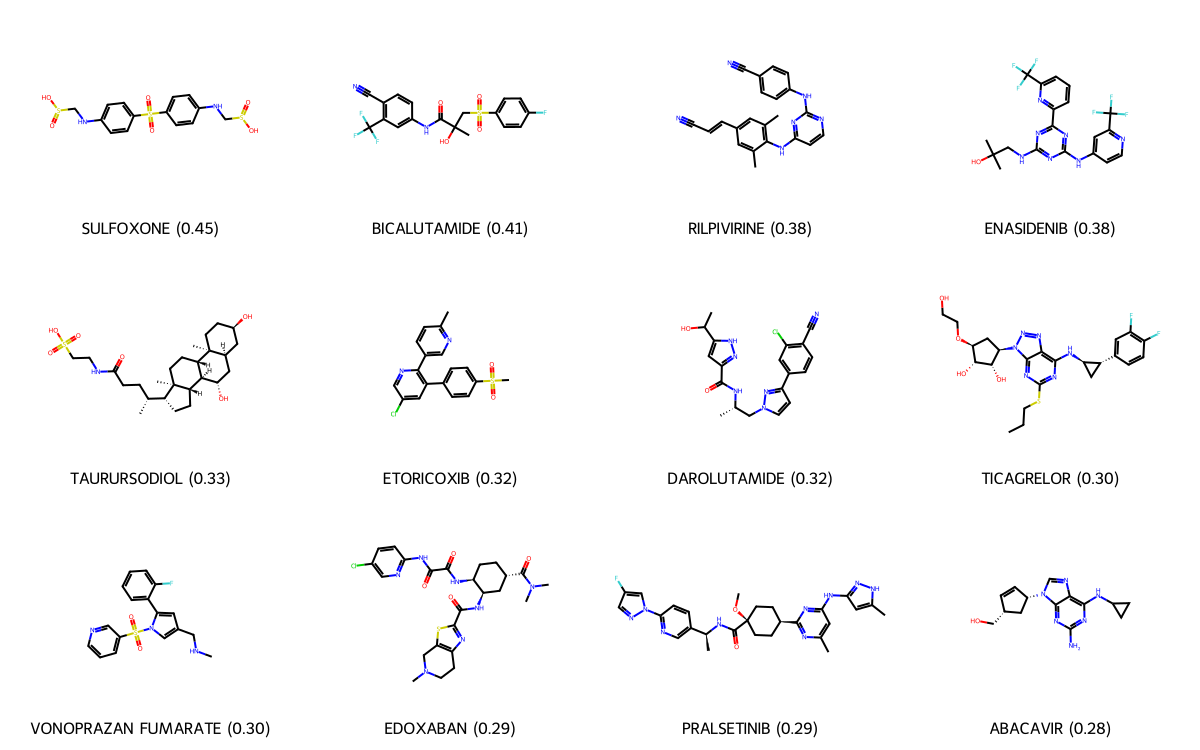

In [ ]:
from rdkit.Chem import Draw

# Is the sulfonamide signal real? Compare frequency in training actives vs inactives
tr = data.copy()
tr["sulf"] = tr.mol.apply(lambda m: m.HasSubstructMatch(sulfonamide))
tr["HA"] = tr.mol.apply(lambda m: m.GetNumHeavyAtoms())
print(tr.groupby("y").agg(n=("y", "size"), sulfonamide=("sulf", "sum"), frac=("sulf", "mean"), median_HA=("HA", "median")).round(2))
print("Library: sulfonamide fraction =", round(cand.sulfonamide.mean(), 2), "| median HA =", cand.HA.median())

short = cand[(~cand.sulfonamide) & (cand.HA >= 20)].head(24).copy()
short["short_rank"] = range(1, len(short) + 1)
print(short[["short_rank", "ML_rank", "name", "ML_score", "maxSim_active", "HA"]].round(2).to_string(index=False))

Draw.MolsToGridImage(list(short.mol[:12]), molsPerRow=4, subImgSize=(300, 250),
                     legends=[f"{r.name} ({r.ML_score:.2f})" for r in short.head(12).itertuples()])

# 7. ML Ranking and Candidate Shortlisting
Rank the approved-drug screen and apply substructure, size, and hinge-motif filters.


ML top 100 -> no sulfonyl + HA>=20: 24 -> with hinge-type motif: 13
 ML_rank                         name  ML_score  maxSim_active  HA
      15                  RILPIVIRINE      0.38           0.37  28
      21                   ENASIDENIB      0.38           0.31  33
      57                   TICAGRELOR      0.30           0.19  36
      64                     EDOXABAN      0.29           0.22  37
      67                  PRALSETINIB      0.29           0.25  39
      72                     ABACAVIR      0.28           0.34  21
      75                  VORASIDENIB      0.28           0.22  27
      77               VALGANCICLOVIR      0.28           0.22  25
      79                  BELUMOSUDIL      0.28           0.28  34
      84                   ETRAVIRINE      0.27           0.31  28
      87 VALGANCICLOVIR HYDROCHLORIDE      0.27           0.21  25
      91                   UBROGEPANT      0.26           0.20  40
      93                   LENIOLISIB      0.26           0.2

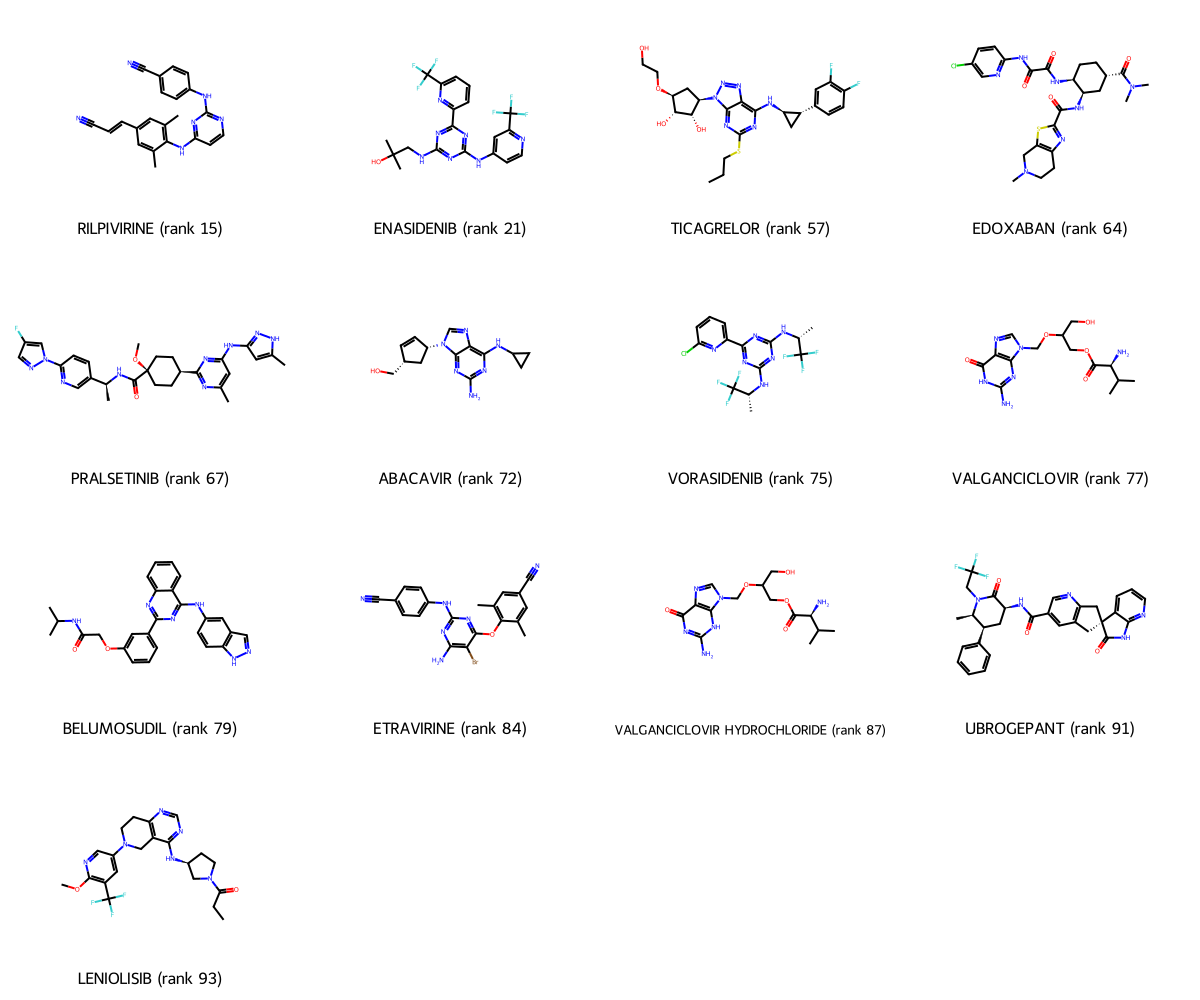

In [ ]:
sulfonyl = Chem.MolFromSmarts("[#16](=O)=O")
hinge_motif = Chem.MolFromSmarts("[nX2]:c-[NX3;H1,H2]")      # ring N next to an NH/NH2-substituted carbon

top100 = cand.head(100).copy()
top100["sulfonyl"] = top100.mol.apply(lambda m: m.HasSubstructMatch(sulfonyl))
top100["hinge_motif"] = top100.mol.apply(lambda m: m.HasSubstructMatch(hinge_motif))

final_short = top100[(~top100.sulfonyl) & (top100.HA >= 20) & (top100.hinge_motif)].reset_index(drop=True)
print(f"ML top 100 -> no sulfonyl + HA>=20: {((~top100.sulfonyl) & (top100.HA >= 20)).sum()} -> with hinge-type motif: {len(final_short)}")
print(final_short[["ML_rank", "name", "ML_score", "maxSim_active", "HA"]].round(2).to_string(index=False))

Draw.MolsToGridImage(list(final_short.mol), molsPerRow=4, subImgSize=(300, 250),
                     legends=[f"{r.name} (rank {r.ML_rank})" for r in final_short.itertuples()])

## 7.1. Candidate Score Distribution
Plot the top-100 score threshold and known-binder positions.


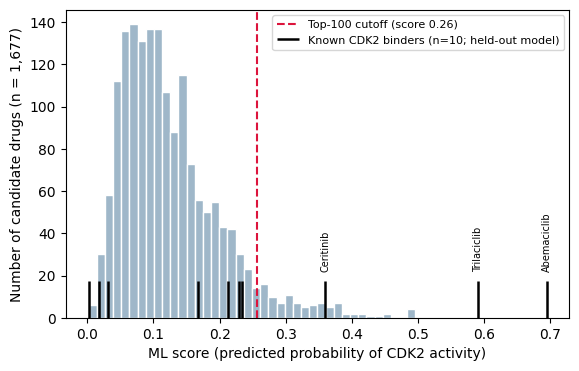

Known binders ranked in the top 100 (of 1,687): 3 of 10
Expected by chance: 0.59; P(>= 3 by chance) = 0.018


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import hypergeom

cut = cand["ML_score"].iloc[99]                    # score of the 100th-ranked candidate
kb  = pool[pool.group == "known"]                  # known binders, scored by the model trained WITHOUT them

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(cand["ML_score"], bins=40, color="#9fb7c9", edgecolor="white")
ymax = ax.get_ylim()[1]
ax.axvline(cut, color="crimson", ls="--", label=f"Top-100 cutoff (score {cut:.2f})")
ax.vlines(kb["ML_score"], 0, ymax * 0.12, color="black", lw=1.8,
          label=f"Known CDK2 binders (n={len(kb)}; held-out model)")
for _, r in kb[kb["rank"] <= 40].iterrows():       # label the best-ranked binders
    ax.text(r["ML_score"], ymax * 0.15, r["name"].title(), rotation=90,
            ha="center", va="bottom", fontsize=7)
ax.set(xlabel="ML score (predicted probability of CDK2 activity)",
       ylabel=f"Number of candidate drugs (n = {len(cand):,})")
ax.legend(loc="upper right", fontsize=8)
plt.savefig("ml_score_distribution.png", dpi=200, bbox_inches="tight"); plt.show()

n_top = int((kb["rank"] <= 100).sum())
print(f"Known binders ranked in the top 100 (of {len(pool):,}): {n_top} of {len(kb)}")
print(f"Expected by chance: {len(kb) * 100 / len(pool):.2f}; P(>= {n_top} by chance) = "
      f"{hypergeom.sf(n_top - 1, len(pool), 100, len(kb)):.3f}")

# 8. Candidate Docking in CDK2 (1H01)
Dock nine shortlisted compounds and controls using smina.


In [ ]:
!wget -q https://sourceforge.net/projects/smina/files/smina.static/download -O smina.static
!chmod u+x smina.static
!ls -l smina.static

-rwxr--r-- 1 root root 9853920 Oct 15  2019 smina.static


In [ ]:
import os, re, subprocess, time, numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem

cand_names = ["RILPIVIRINE","ETRAVIRINE","PRALSETINIB","BELUMOSUDIL","LENIOLISIB",
              "ENASIDENIB","VORASIDENIB","TICAGRELOR","ABACAVIR"]
ref_names = ["PALBOCICLIB","ABEMACICLIB"]
fal_smiles = "CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1"

todo = {}
for _, r in final_short[final_short["name"].isin(cand_names)].iterrows():
    todo[r["name"]] = (r["canonical_smiles"], "candidate")
for _, r in known_cdk2[known_cdk2["name"].isin(ref_names)].iterrows():
    todo[r["name"]] = (r["canonical_smiles"], "known CDK2 binder")
todo["FAL (cognate)"] = (fal_smiles, "cognate")
print(len(todo), "compounds:", list(todo))

# Leu83 backbone atoms from the receptor
rec = Chem.MolFromPDBFile("1H01-receptor.pdb", removeHs=False, sanitize=False)
rc = rec.GetConformer()
hinge = {}
for a in rec.GetAtoms():
    info = a.GetPDBResidueInfo()
    if info.GetChainId() == "A" and info.GetResidueNumber() == 83 and info.GetName().strip() in ("N", "O"):
        hinge["Leu83_" + info.GetName().strip()] = np.array(rc.GetAtomPosition(a.GetIdx()))
print("Hinge atoms:", list(hinge))

def leu83(mol, cutoff=3.5):
    conf = mol.GetConformer()
    polar = np.array([list(conf.GetAtomPosition(a.GetIdx())) for a in mol.GetAtoms() if a.GetSymbol() in ("N", "O")])
    d = {k: float(np.min(np.linalg.norm(polar - v, axis=1))) for k, v in hinge.items()}
    return sum(x <= cutoff for x in d.values()), d

def embed(smi):
    m = Chem.AddHs(Chem.MolFromSmiles(smi))
    if AllChem.EmbedMolecule(m, randomSeed=42) != 0:
        return None
    AllChem.MMFFOptimizeMolecule(m, maxIters=2000)
    return m

SEEDS = [1, 2, 3]            # use [1] for a quick first test
os.makedirs("dock", exist_ok=True)
rows, t0 = [], time.time()
for name, (smi, kind) in todo.items():
    fn = re.sub(r"[^A-Za-z0-9]+", "_", name)
    m = embed(smi)
    if m is None:
        print(name, ": 3D embedding failed"); continue
    m.SetProp("_Name", name)
    w = Chem.SDWriter(f"dock/{fn}.sdf"); w.write(m); w.close()
    for seed in SEEDS:
        out = f"dock/{fn}_seed{seed}.sdf"
        subprocess.run(["./smina.static", "-r", "1H01-receptor.pdb", "-l", f"dock/{fn}.sdf",
                        "--autobox_ligand", "1H01-ligand.pdb", "-o", out, "--seed", str(seed),
                        "--exhaustiveness", "8", "--num_modes", "9", "-q"], check=True, capture_output=True)
        for pose_i, p in enumerate(Chem.SDMolSupplier(out, removeHs=True), 1):
            if p is None: continue
            n_c, d = leu83(p)
            rows.append(dict(name=name, kind=kind, seed=seed, pose=pose_i,
                             score=float(p.GetProp("minimizedAffinity")), n_contacts=n_c, **d))
    print(f"{name:<18} done ({(time.time() - t0) / 60:.1f} min elapsed)")

poses_df = pd.DataFrame(rows)

# One summary row per compound
summ = []
for (kind, name), g in poses_df.groupby(["kind", "name"]):
    h = g[g.n_contacts >= 1].sort_values(["n_contacts", "score"], ascending=[False, True])
    top = h.iloc[0] if len(h) else None
    summ.append(dict(kind=kind, name=name, best_score=g.score.min(),
                     hinge_contacts=int(top.n_contacts) if top is not None else 0,
                     hinge_pose_score=top.score if top is not None else np.nan,
                     Leu83_N=round(top.Leu83_N, 2) if top is not None else np.nan,
                     Leu83_O=round(top.Leu83_O, 2) if top is not None else np.nan,
                     seeds_with_hinge=f"{g[g.n_contacts >= 1].seed.nunique()}/{len(SEEDS)}"))
summary = pd.DataFrame(summ).sort_values(["kind", "hinge_contacts", "best_score"], ascending=[True, False, True])

os.makedirs("/content/drive/MyDrive/CDK2_project/dock", exist_ok=True)
poses_df.to_csv("/content/drive/MyDrive/CDK2_project/dock_all_poses.csv", index=False)
summary.to_csv("/content/drive/MyDrive/CDK2_project/dock_summary.csv", index=False)
!cp dock/*.sdf /content/drive/MyDrive/CDK2_project/dock/
summary.round(2)

12 compounds: ['RILPIVIRINE', 'ENASIDENIB', 'TICAGRELOR', 'PRALSETINIB', 'ABACAVIR', 'VORASIDENIB', 'BELUMOSUDIL', 'ETRAVIRINE', 'LENIOLISIB', 'PALBOCICLIB', 'ABEMACICLIB', 'FAL (cognate)']
Hinge atoms: ['Leu83_N', 'Leu83_O']
RILPIVIRINE        done (5.1 min elapsed)
ENASIDENIB         done (11.8 min elapsed)
TICAGRELOR         done (21.6 min elapsed)
PRALSETINIB        done (34.8 min elapsed)
ABACAVIR           done (36.6 min elapsed)
VORASIDENIB        done (40.4 min elapsed)
BELUMOSUDIL        done (47.2 min elapsed)
ETRAVIRINE         done (51.3 min elapsed)
LENIOLISIB         done (56.7 min elapsed)
PALBOCICLIB        done (62.0 min elapsed)
ABEMACICLIB        done (71.3 min elapsed)
FAL (cognate)      done (77.4 min elapsed)


,kind,name,best_score,hinge_contacts,hinge_pose_score,Leu83_N,Leu83_O,seeds_with_hinge
3,candidate,ETRAVIRINE,-9.75,2,-8.61,3.42,3.37,3/3
6,candidate,RILPIVIRINE,-9.61,2,-9.61,3.14,2.80,3/3
7,candidate,TICAGRELOR,-9.50,2,-9.44,3.15,2.83,2/3
0,candidate,ABACAVIR,-8.43,2,-8.08,3.01,3.07,3/3
1,candidate,BELUMOSUDIL,-11.10,1,-10.88,3.88,3.00,3/3
2,candidate,ENASIDENIB,-10.62,1,-10.25,5.21,3.28,1/3
4,candidate,LENIOLISIB,-10.28,1,-9.59,4.15,3.48,1/3
5,candidate,PRALSETINIB,-9.84,1,-9.84,3.82,2.99,3/3
8,candidate,VORASIDENIB,-9.22,0,NaN,NaN,NaN,0/3
9,cognate,FAL (cognate),-9.62,2,-8.57,2.99,2.81,3/3


## 8.1. Pose Quality and Leu83 Contacts
Assess docked poses, hinge interactions, and comparisons with the FAL crystal structure.


In [ ]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

pose_files = ["dock/FAL_cognate__seed1.sdf", "dock/FAL_cognate__seed2.sdf", "dock/FAL_cognate__seed3.sdf"]

tmpl = Chem.MolFromSmiles("CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1")
crystal = AllChem.AssignBondOrdersFromTemplate(tmpl, Chem.MolFromPDBFile("1H01-ligand.pdb", removeHs=True))

rec = Chem.MolFromPDBFile("1H01-receptor.pdb", removeHs=False, sanitize=False)
rc = rec.GetConformer()
hinge = {}
for a in rec.GetAtoms():
    i = a.GetPDBResidueInfo()
    if i.GetChainId() == "A" and i.GetResidueNumber() == 83 and i.GetName().strip() in ("N", "O"):
        hinge["Leu83_" + i.GetName().strip()] = np.array(rc.GetAtomPosition(a.GetIdx()))

def contacts(m):
    c = m.GetConformer()
    P = [np.array(c.GetAtomPosition(a.GetIdx())) for a in m.GetAtoms() if a.GetSymbol() in ("N", "O")]
    return {k: min(np.linalg.norm(v - p) for p in P) for k, v in hinge.items()}

rows = []
for f in pose_files:
    for k, p in enumerate(Chem.SDMolSupplier(f, removeHs=True), 1):
        d = contacts(p)
        rows.append(dict(file=f, pose=k, score=float(p.GetProp("minimizedAffinity")),
                         rmsd=rdMolAlign.CalcRMS(p, crystal), n_contacts=sum(v <= 3.5 for v in d.values()),
                         N=round(d["Leu83_N"], 2), O=round(d["Leu83_O"], 2)))
import pandas as pd
r = pd.DataFrame(rows)
print(r.round(2).to_string(index=False))
print("\nBest-scoring pose with both contacts, per file:")
print(r[r.n_contacts == 2].sort_values("score").groupby("file").head(1).round(2).to_string(index=False))

                       file  pose  score  rmsd  n_contacts    N    O
dock/FAL_cognate__seed1.sdf     1  -9.60  3.60           0 5.46 5.07
dock/FAL_cognate__seed1.sdf     2  -9.56  3.18           0 5.45 4.91
dock/FAL_cognate__seed1.sdf     3  -9.33  5.40           0 7.44 5.28
dock/FAL_cognate__seed1.sdf     4  -9.16  8.70           0 6.56 6.27
dock/FAL_cognate__seed1.sdf     5  -9.06  5.03           0 8.18 5.81
dock/FAL_cognate__seed1.sdf     6  -8.99  8.67           0 7.56 6.80
dock/FAL_cognate__seed1.sdf     7  -8.95  3.06           0 5.58 5.13
dock/FAL_cognate__seed1.sdf     8  -8.85  7.86           1 5.43 3.29
dock/FAL_cognate__seed1.sdf     9  -8.69  2.63           0 5.42 4.97
dock/FAL_cognate__seed2.sdf     1  -9.45  3.61           0 5.54 5.12
dock/FAL_cognate__seed2.sdf     2  -9.32  3.01           0 5.36 4.84
dock/FAL_cognate__seed2.sdf     3  -9.17  4.97           0 7.81 5.43
dock/FAL_cognate__seed2.sdf     4  -9.00  5.86           0 7.55 5.42
dock/FAL_cognate__seed2.sdf     5 

# 9. Lead Candidate: Rilpivirine
Visualize rilpivirine poses and compare its binding motif with FAL.


/usr/local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35:18] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[19:35

 seed  pose  score  n    N    O
    2     1  -9.61  2 3.14 2.80
    2     9  -8.76  2 3.19 3.15
    1     6  -8.96  1 4.16 3.41

Pose 1: -9.61 kcal/mol | 2 Leu83 contact(s) | Leu83 N 3.14 Å, Leu83 O 2.80 Å  (seed 2, pose 1)


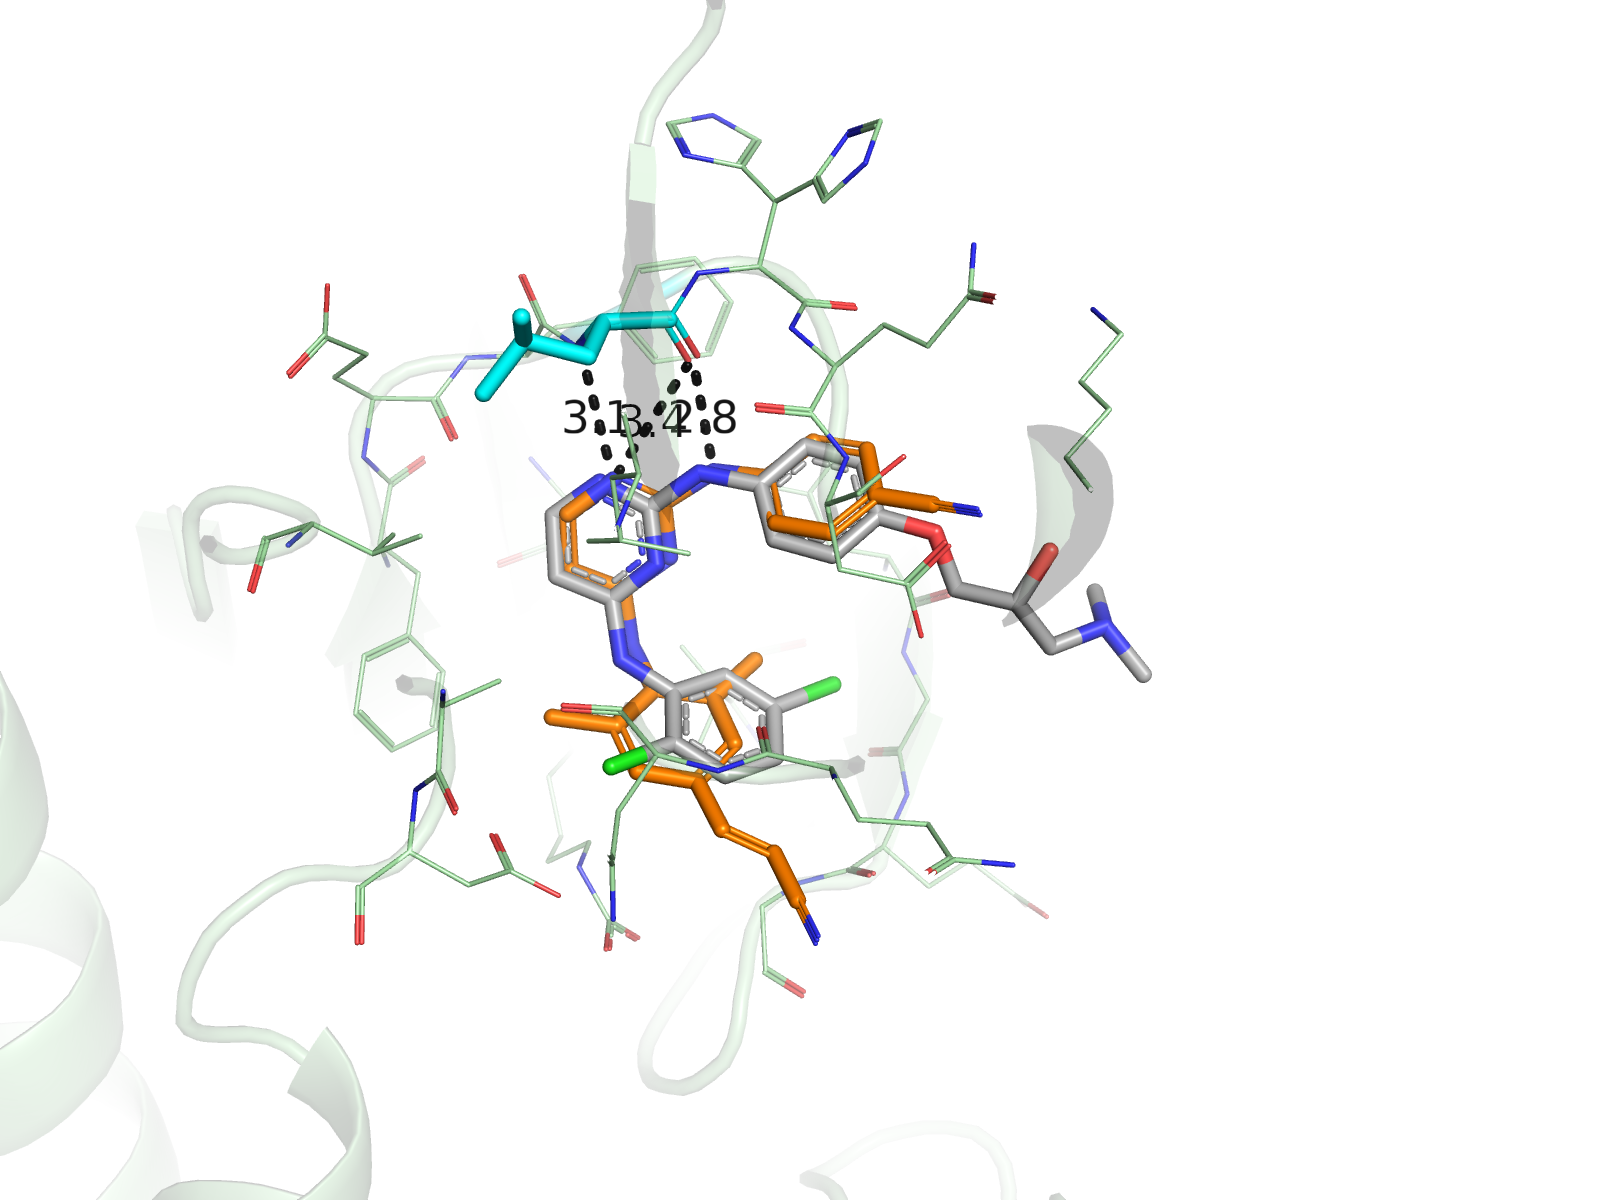


Pose 2: -8.76 kcal/mol | 2 Leu83 contact(s) | Leu83 N 3.19 Å, Leu83 O 3.15 Å  (seed 2, pose 9)


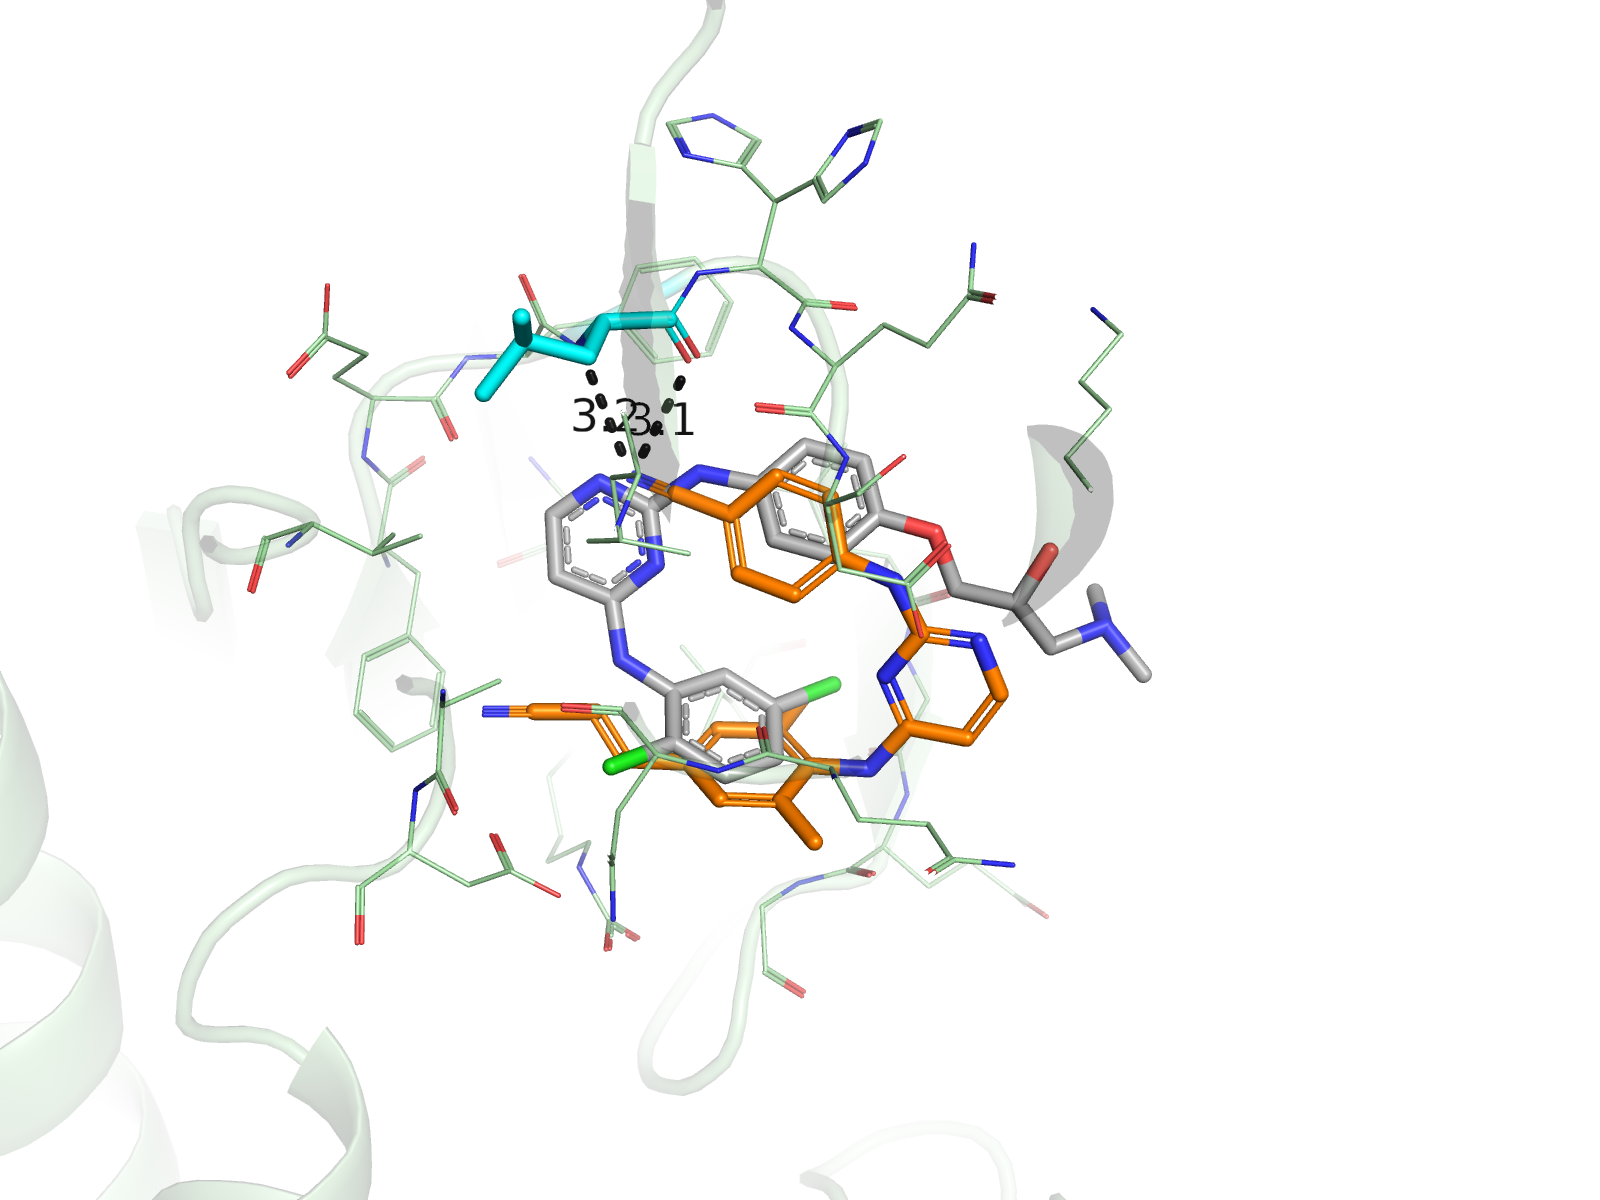


Pose 3: -8.96 kcal/mol | 1 Leu83 contact(s) | Leu83 N 4.16 Å, Leu83 O 3.41 Å  (seed 1, pose 6)


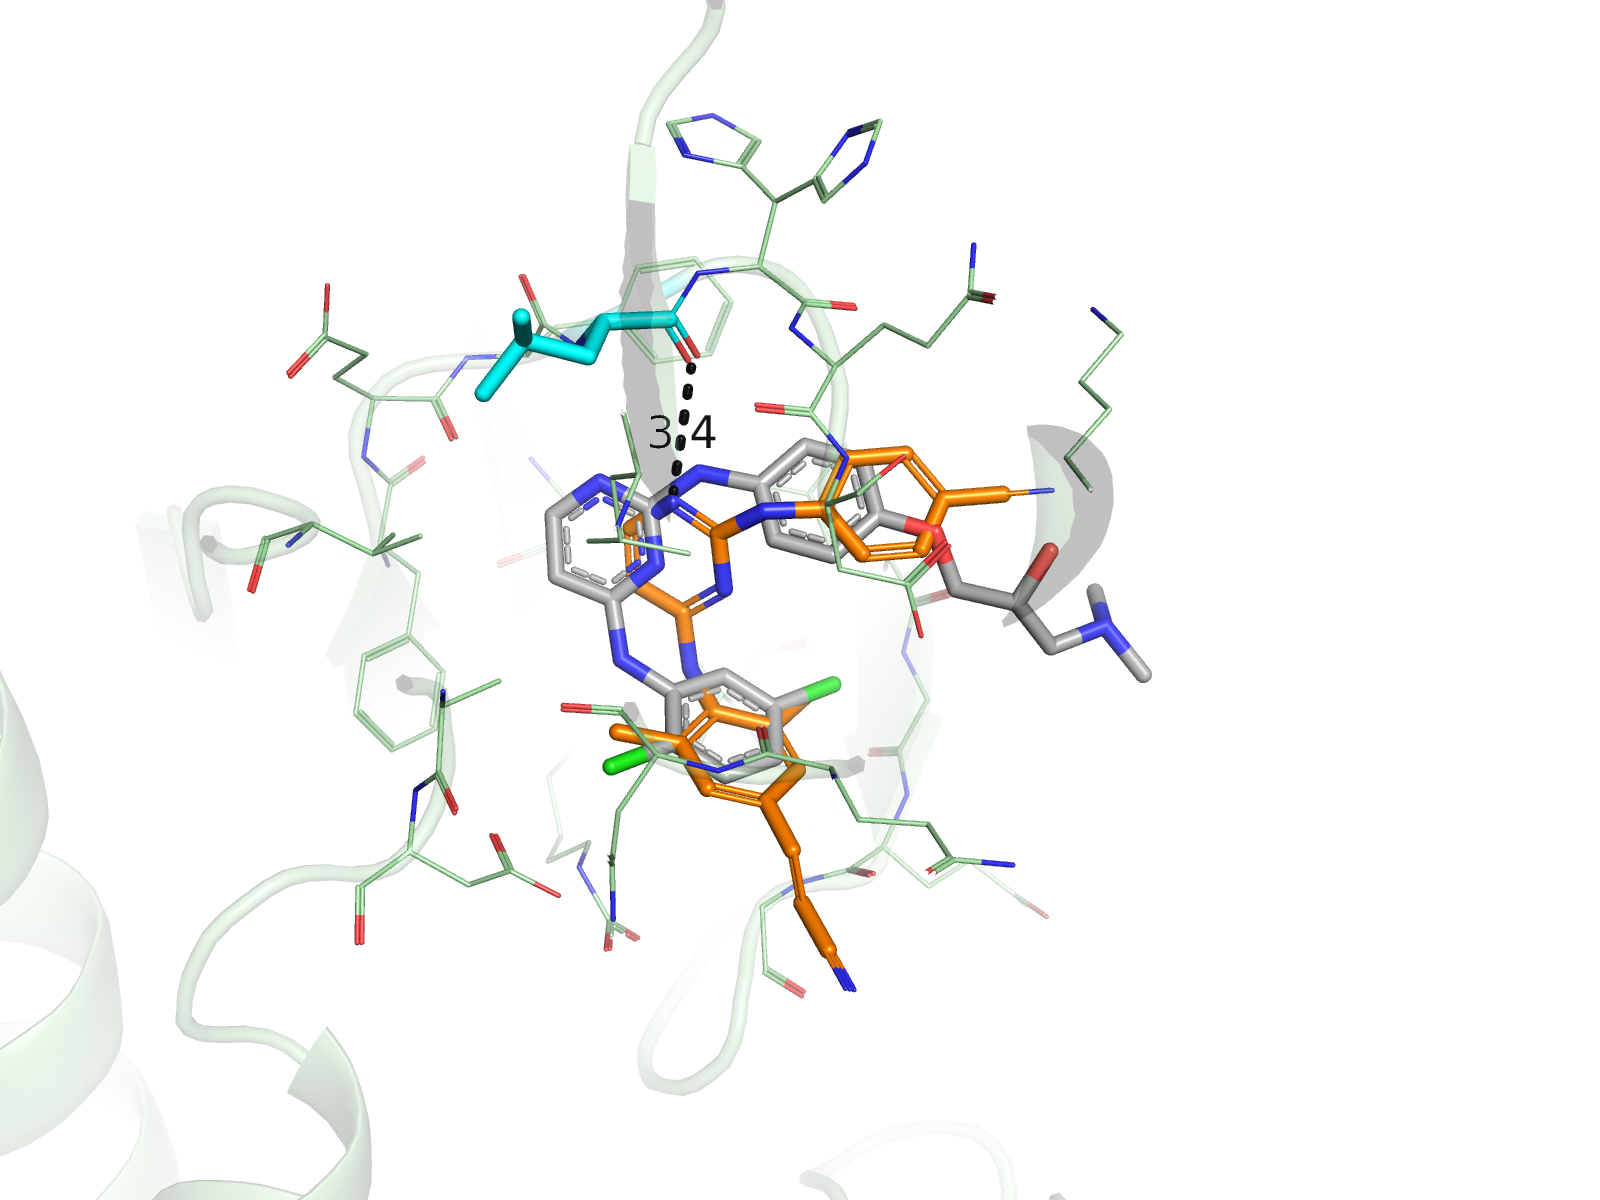


Grey = crystal FAL | Orange = docked rilpivirine | Cyan = Leu83 | Dashes = contacts ≤ 3.5 Å


In [ ]:
import glob, os, re
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolAlign
from pymol import cmd
from IPython.display import Image, display

NAME, N_SHOW = "RILPIVIRINE", 3
os.makedirs("pose_figs", exist_ok=True)

# --- Leu83 backbone atoms ---
rec = Chem.MolFromPDBFile("1H01-receptor.pdb", removeHs=False, sanitize=False)
rc = rec.GetConformer(); hinge = {}
for a in rec.GetAtoms():
    i = a.GetPDBResidueInfo()
    if i.GetChainId() == "A" and i.GetResidueNumber() == 83 and i.GetName().strip() in ("N", "O"):
        hinge[i.GetName().strip()] = np.array(rc.GetAtomPosition(a.GetIdx()))

def contacts(m):
    c = m.GetConformer()
    P = [np.array(c.GetAtomPosition(a.GetIdx())) for a in m.GetAtoms() if a.GetSymbol() in ("N", "O")]
    return {k: min(np.linalg.norm(v - p) for p in P) for k, v in hinge.items()}

# --- collect every pose from all seeds ---
cands = []
for f in sorted(glob.glob(f"dock/{NAME}_seed*.sdf")):
    seed = int(re.search(r"seed(\d+)", f).group(1))
    for k, p in enumerate(Chem.SDMolSupplier(f, removeHs=True), 1):
        d = contacts(p)
        cands.append(dict(mol=p, seed=seed, pose=k, score=float(p.GetProp("minimizedAffinity")),
                          n=sum(v <= 3.5 for v in d.values()), N=d["N"], O=d["O"]))

# rank: most Leu83 contacts first, then best score
# (for a pure score ranking, use:  key=lambda c: c["score"])
cands.sort(key=lambda c: (-c["n"], c["score"]))

# keep the top 3 that differ from each other by > 1 A RMSD
chosen = []
for c in cands:
    if all(rdMolAlign.CalcRMS(c["mol"], x["mol"]) > 1.0 for x in chosen):
        chosen.append(c)
    if len(chosen) == N_SHOW: break

print(pd.DataFrame([{k: v for k, v in c.items() if k != "mol"} for c in chosen]).round(2).to_string(index=False))

# --- render and show each pose on its own ---
for r, c in enumerate(chosen, 1):
    sdf = f"pose_figs/{NAME}_top{r}.sdf"
    w = Chem.SDWriter(sdf); w.write(c["mol"]); w.close()
    cmd.reinitialize(); cmd.bg_color("white")
    cmd.load("1H01-receptor.pdb", "rec"); cmd.load("1H01-ligand.pdb", "xtal"); cmd.load(sdf, "pose")
    cmd.hide("everything")
    cmd.show("cartoon", "rec"); cmd.color("palegreen", "rec"); cmd.set("cartoon_transparency", 0.75)
    cmd.select("pocket", "byres (rec within 5 of xtal)"); cmd.show("line", "pocket")
    cmd.show("sticks", "xtal"); cmd.color("grey70", "xtal and elem C")
    cmd.show("sticks", "pose"); cmd.color("orange", "pose and elem C")
    cmd.show("sticks", "rec and resi 83"); cmd.color("cyan", "rec and resi 83 and elem C")
    cmd.util.cnc("all"); cmd.set("stick_radius", 0.2)
    cmd.distance("hb", "pose and elem N+O", "rec and resi 83 and name N+O", 3.5, mode=0)
    cmd.set("dash_color", "black"); cmd.set("dash_width", 3); cmd.set("label_size", 18, "hb")
    cmd.orient("xtal"); cmd.zoom("xtal", 6); cmd.clip("slab", 14); cmd.set("ray_shadow", 0)
    png = f"pose_figs/{NAME}_top{r}.png"
    cmd.png(png, width=1600, height=1200, dpi=300, ray=1)
    print(f"\nPose {r}: {c['score']:.2f} kcal/mol | {c['n']} Leu83 contact(s) | "
          f"Leu83 N {c['N']:.2f} Å, Leu83 O {c['O']:.2f} Å  (seed {c['seed']}, pose {c['pose']})")
    display(Image(filename=png, width=800))

print("\nGrey = crystal FAL | Orange = docked rilpivirine | Cyan = Leu83 | Dashes = contacts ≤ 3.5 Å")

In [ ]:
import glob, zipfile
from google.colab import files

print(sorted(glob.glob("pose_figs/RILPIVIRINE_top*.png")))
with zipfile.ZipFile("rilpivirine_poses.zip", "w") as z:
    for f in sorted(glob.glob("pose_figs/RILPIVIRINE_top*.png")):
        z.write(f)
files.download("rilpivirine_poses.zip")

['pose_figs/RILPIVIRINE_top1.png', 'pose_figs/RILPIVIRINE_top2.png', 'pose_figs/RILPIVIRINE_top3.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Core found in both: True


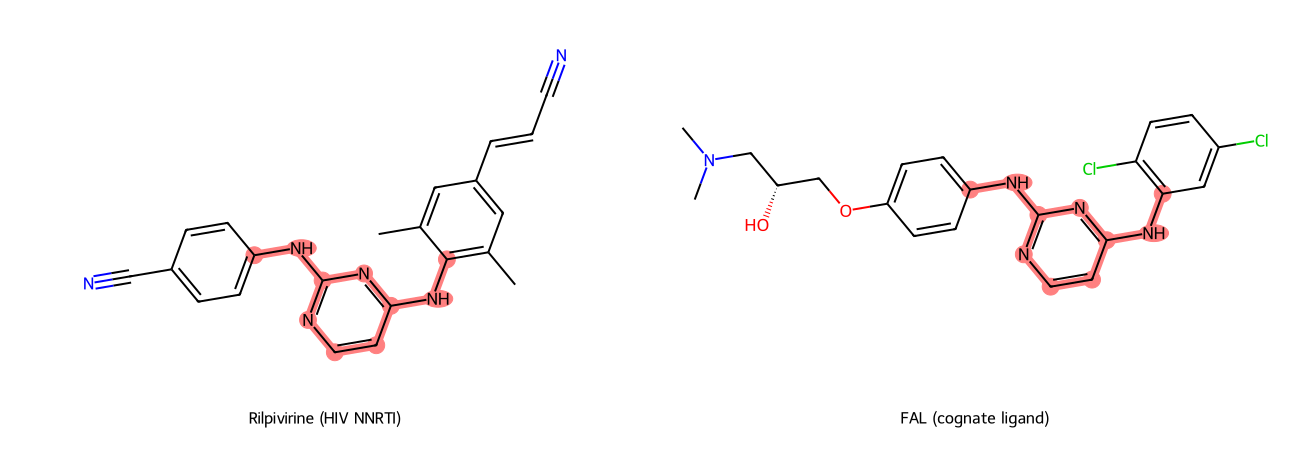

Tanimoto to FAL: 0.28


In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw, AllChem, DataStructs, rdDepictor
from IPython.display import display

rilp = Chem.MolFromSmiles("Cc1cc(/C=C/C#N)cc(C)c1Nc1ccnc(Nc2ccc(C#N)cc2)n1")   # rilpivirine
fal  = Chem.MolFromSmiles("CN(C)C[C@@H](O)COc1ccc(Nc2nccc(Nc3cc(Cl)ccc3Cl)n2)cc1")
core = Chem.MolFromSmarts("c-[NH]-c1nccc(-[NH]-c)n1")

rdDepictor.Compute2DCoords(fal)
rdDepictor.GenerateDepictionMatching2DStructure(rilp, fal, refPatt=core)

mols = [rilp, fal]
atoms = [list(m.GetSubstructMatch(core)) for m in mols]
print("Core found in both:", all(len(a) > 0 for a in atoms))
bonds = [[b.GetIdx() for b in m.GetBonds() if b.GetBeginAtomIdx() in a and b.GetEndAtomIdx() in a]
         for m, a in zip(mols, atoms)]

img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(650, 450), useSVG=False,
                           legends=["Rilpivirine (HIV NNRTI)", "FAL (cognate ligand)"],
                           highlightAtomLists=atoms, highlightBondLists=bonds)

# save whichever type RDKit returned
if hasattr(img, "save"):
    img.save("structures.png")
else:
    with open("structures.png", "wb") as f:
        f.write(img.data)
display(img)

g = AllChem.GetMorganGenerator()
print("Tanimoto to FAL:", round(DataStructs.TanimotoSimilarity(g.GetFingerprint(rilp), g.GetFingerprint(fal)), 2))